japanize_matplotlib が見つかりません。日本語表示のためにインストールを検討してください。
シミュレーションを開始します...

===== シミュレーション中: 介入 = 0 =====

===== シミュレーション中: 介入 = 1 =====

===== シミュレーション中: 介入 = 2 =====

シミュレーション完了。

詳細ステップデータが 'simulation_all_actions_step_data.csv' に保存されました。
エピソードサマリーデータが 'simulation_all_actions_episode_summary.csv' に保存されました。

--- CSVデータからの分析と可視化 ---

--- 集計表 (介入別、誠実性スコア別) ---
   simulated_action  co_score  num_episodes  completion_rate  \
0                 0       0.2           100             23.0   
1                 0       0.5           100             60.0   
2                 0       0.8           100             97.0   
3                 1       0.2           100            100.0   
4                 1       0.5           100            100.0   
5                 1       0.8           100            100.0   
6                 2       0.2           100            100.0   
7                 2       0.5           100            100.0   
8                 2       0.8           100            100.0   

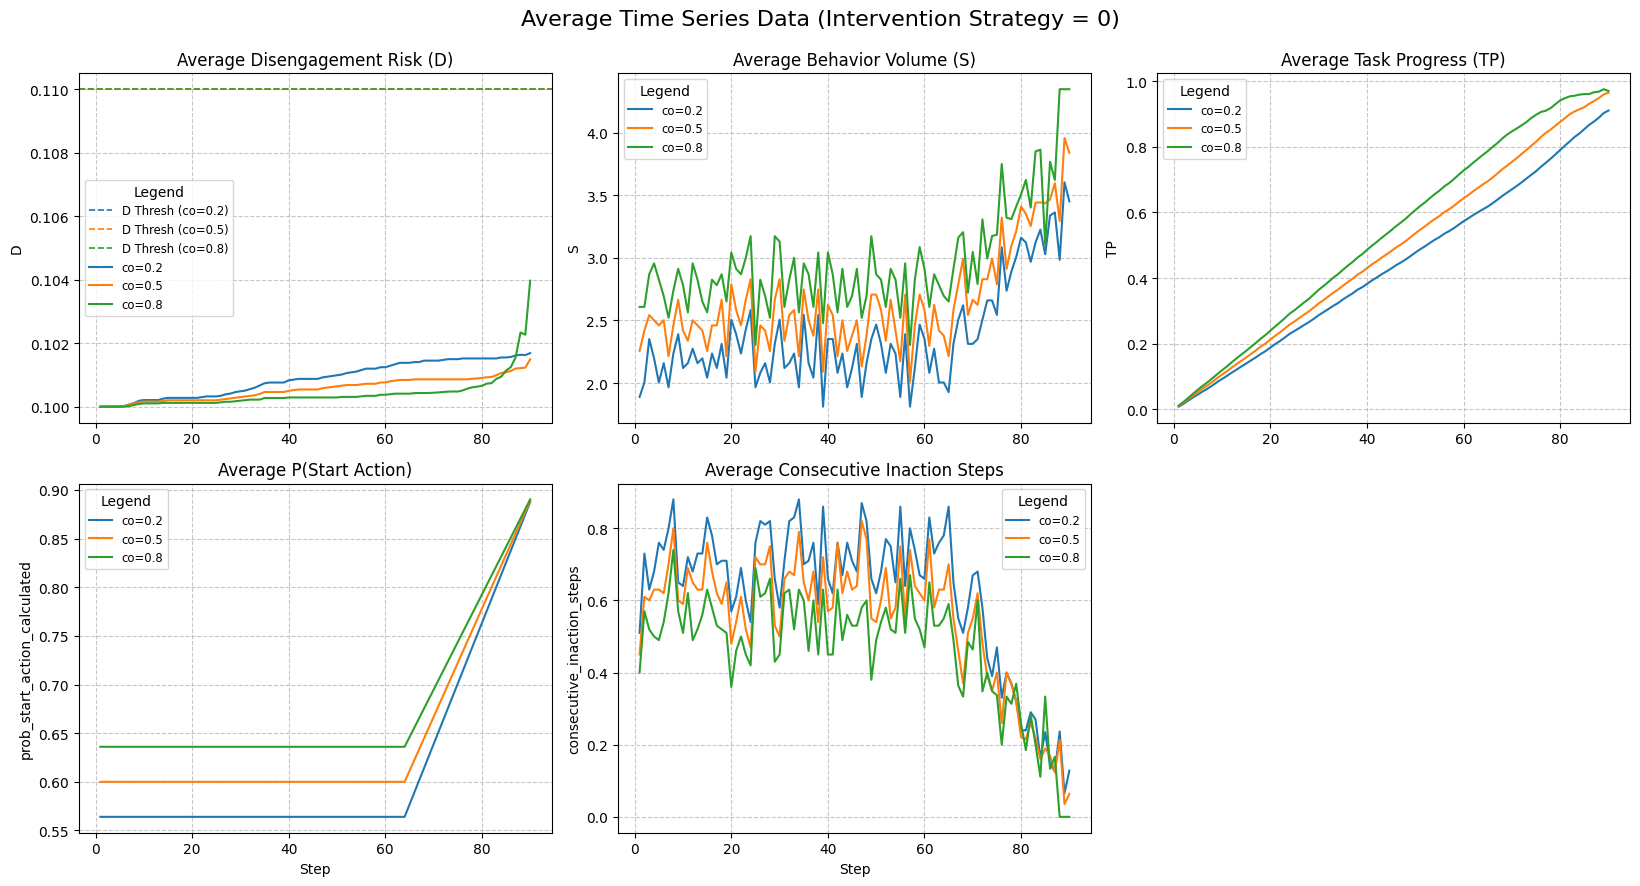


--- Generating plots for Intervention Action = 1 ---


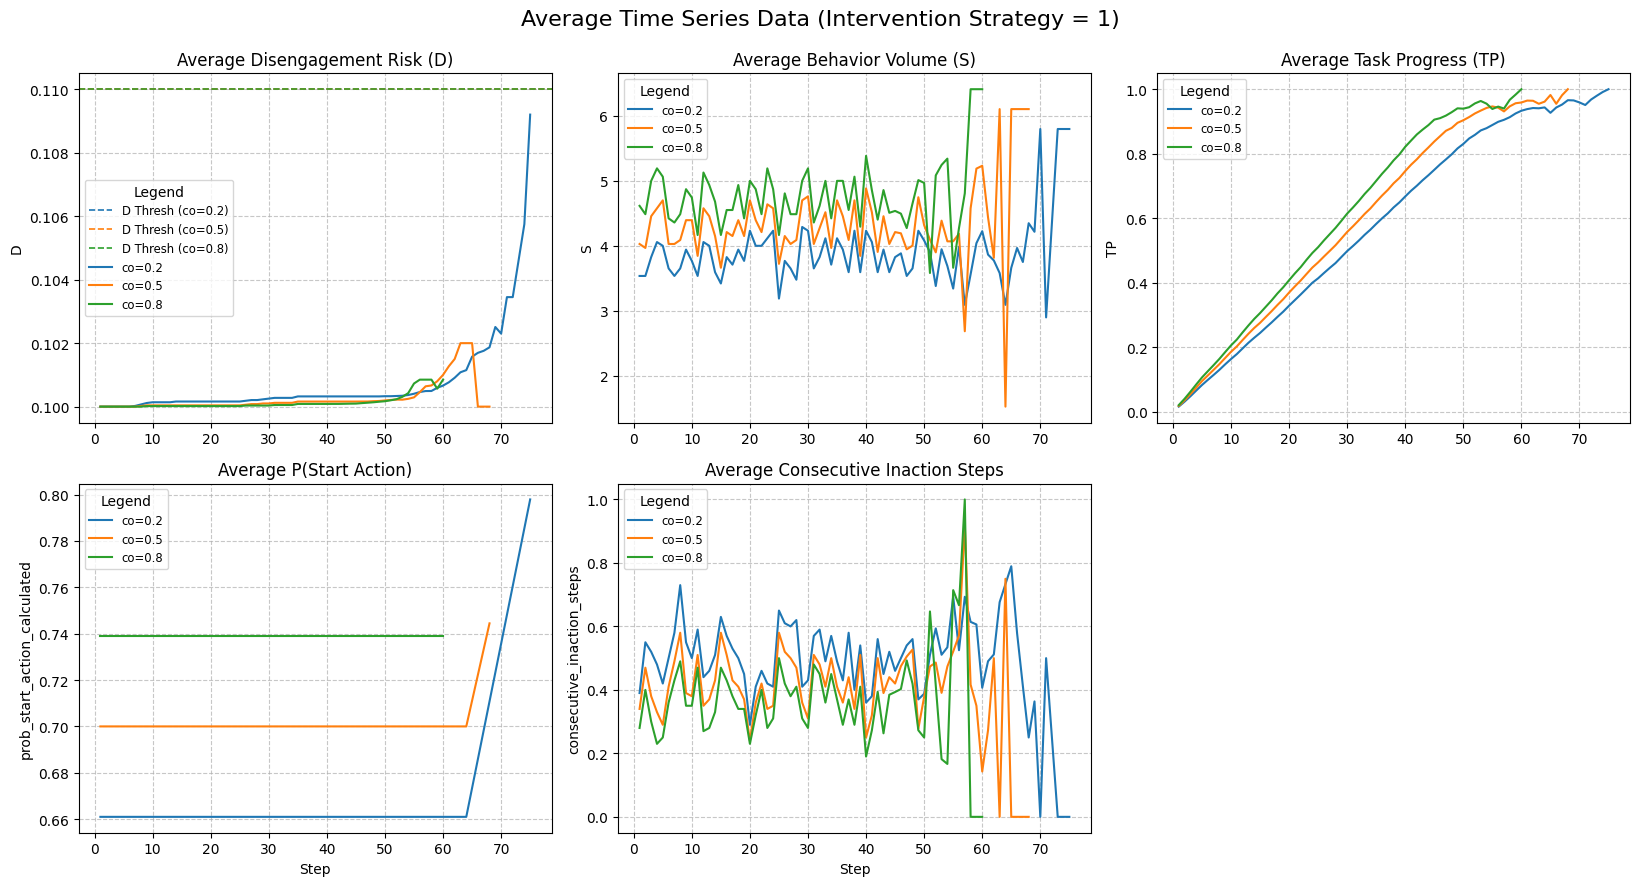


--- Generating plots for Intervention Action = 2 ---


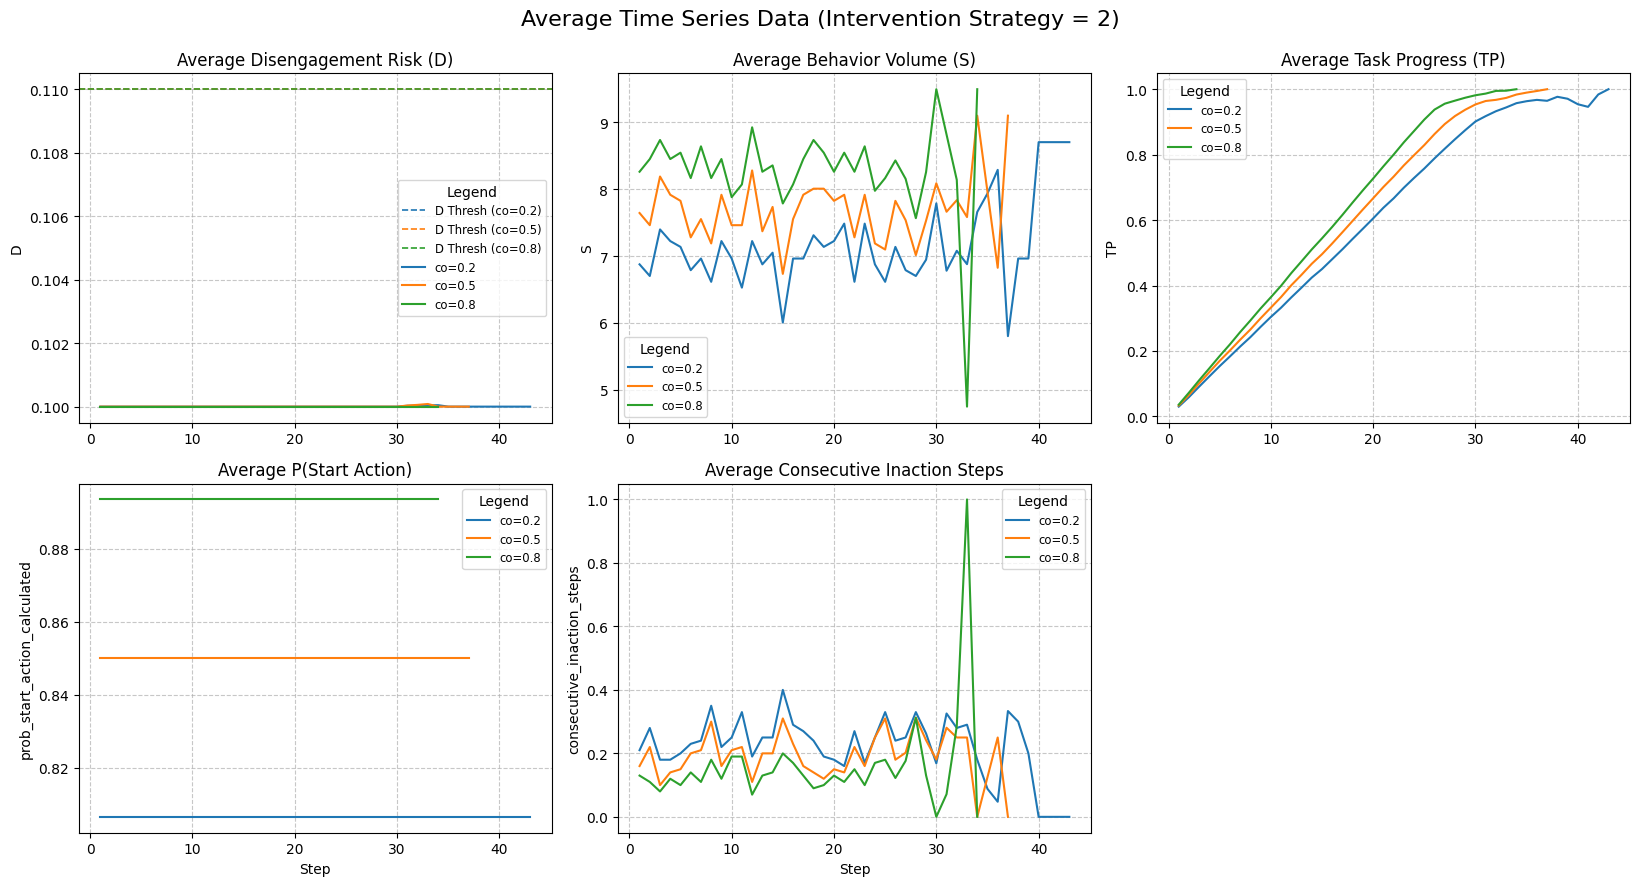

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import warnings
import pandas as pd

# Matplotlibの日本語設定 (環境によっては別途フォントのインストールや設定が必要な場合があります)
try:
    import japanize_matplotlib
    japanize_matplotlib.japanize()
except ImportError:
    print("japanize_matplotlib が見つかりません。日本語表示のためにインストールを検討してください。")
    pass

# ↓↓↓↓↓↓ この部分を追加・確認してください ↓↓↓↓↓↓
pd.set_option('display.max_rows', None)      # 表示する行数の上限を撤廃
pd.set_option('display.max_columns', None)   # 表示する列数の上限を撤廃
pd.set_option('display.width', None)         # 表示幅の自動調整（折り返しを減らす）
pd.set_option('display.max_colwidth', None) # 列内の文字列の最大表示幅を撤廃 (長い文字列も省略しない)
# ↑↑↑↑↑↑ ここまでを追加・確認 ↑↑↑↑↑↑

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

class SimplifiedTaskJITAIEnv(gym.Env):
    metadata = {'render_modes': ['human'], 'render_fps': 4}

    def __init__(self,
                 # --- 環境設定 ---
                 n_actions=3,
                 max_episode_length=90,
                 seed=0,
                 # --- 性格特性とタスク ---
                 co_score=0.5,
                 total_task_work=230.0,
                 # --- 離脱リスク(D)関連のベース ---
                 delta_d_base=0.02,
                 epsilon_d_base=0.05,
                 D_threshold_base=0.11,
                 # --- NEW: 非行動によるD増加関連のパラメータ ---
                 d_increase_on_inaction_base=0.002, # 非行動が続いた場合のDの増加量のベース
                 co_effect_on_d_increase_inaction_multiplier=-0.5, # 誠実性高いとD増加しにくいように負の値
                 inaction_steps_threshold=5,
                 # --- 行動開始確率関連のベース ---
                 base_prob_start_action_base=0.6,
                 intervention_boost_to_prob_start_base=[0.0, 0.1, 0.25],
                 urgency_factor_base=0.3,
                 # --- 行動量(S)関連のベース ---
                 mu_s_base=4.1,
                 rho1_base=2.0,
                 rho2_base=5.0,
                 # --- co_scoreの影響係数 (multiplier) ---
                 co_effect_on_delta_d_multiplier=0.3,
                 co_effect_on_epsilon_d_multiplier=0.5,
                 co_effect_on_D_threshold_multiplier=1.5,
                 co_effect_on_base_prob_start_multiplier=0.2,
                 co_effect_on_intervention_boost_multiplier=0.1,
                 co_effect_on_urgency_factor_multiplier=-0.4,
                 co_effect_on_mu_s_multiplier=0.2,
                 co_effect_on_rho1_multiplier=0.1,
                 co_effect_on_rho2_multiplier=0.1,
                 # --- 状態変数の初期値 ---
                 init_d=0.1,
                 # --- 観測 ---
                 chosen_obs_names=['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
                 # --- 確率的S (オプション) ---
                 n_version=0,
                 s_noise_std_base=0.0,
                 co_effect_on_s_noise_std_multiplier=0.0,
                 intervention_cost=0.1,
            
                 ):
        super().__init__()

        self.max_episode_length = max_episode_length
        self.n_actions = n_actions
        self.chosen_obs_names = chosen_obs_names
        self.n_version = n_version

        self.co_score = np.clip(co_score, 0.0, 1.0)
        self.current_CO = self.co_score

        self.delta_d_base = delta_d_base
        self.epsilon_d_base = epsilon_d_base
        self.D_threshold_base = D_threshold_base
        self.d_increase_on_inaction_base = d_increase_on_inaction_base
        self.co_effect_on_d_increase_inaction_multiplier = co_effect_on_d_increase_inaction_multiplier
        self.inaction_steps_threshold = inaction_steps_threshold

        self.base_prob_start_action_base = base_prob_start_action_base
        self.intervention_boost_to_prob_start_base = np.array(intervention_boost_to_prob_start_base)
        if len(self.intervention_boost_to_prob_start_base) != n_actions:
            raise ValueError("Length of intervention_boost_to_prob_start_base must match n_actions.")
        self.urgency_factor_base = urgency_factor_base
        self.mu_s_base = mu_s_base
        self.rho1_base = rho1_base
        self.rho2_base = rho2_base
        self.total_task_work = total_task_work
        self.s_noise_std_base = s_noise_std_base

        self.co_effect_on_delta_d_multiplier = co_effect_on_delta_d_multiplier
        self.co_effect_on_epsilon_d_multiplier = co_effect_on_epsilon_d_multiplier
        self.co_effect_on_D_threshold_multiplier = co_effect_on_D_threshold_multiplier
        self.co_effect_on_base_prob_start_multiplier = co_effect_on_base_prob_start_multiplier
        self.co_effect_on_intervention_boost_multiplier = co_effect_on_intervention_boost_multiplier
        self.co_effect_on_urgency_factor_multiplier = co_effect_on_urgency_factor_multiplier
        self.co_effect_on_mu_s_multiplier = co_effect_on_mu_s_multiplier
        self.co_effect_on_rho1_multiplier = co_effect_on_rho1_multiplier
        self.co_effect_on_rho2_multiplier = co_effect_on_rho2_multiplier
        self.co_effect_on_s_noise_std_multiplier = co_effect_on_s_noise_std_multiplier

        self.init_d = init_d
        self.init_s = 0.0
        self.init_task_progress = 0.0

        self.seed = seed
        self.rng1 = None

        self.current_t = 0
        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.consecutive_inaction_steps = 0

        self.action_space = spaces.Discrete(self.n_actions)
        min_obs_values, max_obs_values = self.extract_min_max()
        self.observation_space = spaces.Box(
            low=np.array(min_obs_values, dtype=np.float32),
            high=np.array(max_obs_values, dtype=np.float32),
            dtype=np.float32
        )
        self._initialize_operational_params()
        self.intervention_cost = intervention_cost # インスタンス変数として設定


    def _initialize_operational_params(self):
        self.delta_d, self.epsilon_d, self.D_threshold = 0.0, 0.0, 0.0
        self.base_prob_start_action = 0.0
        self.intervention_boost_to_prob_start = np.zeros(self.n_actions)
        self.urgency_factor = 0.0
        self.mu_s, self.rho1, self.rho2 = 0.0, 0.0, 0.0
        self.s_noise_std = 0.0


    def _adjust_param(self, base_val, multiplier, co_factor):
        return base_val * (1 + co_factor * multiplier)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None:
            self.seed = seed
        # Adding current_t to seed ensures that if reset is called multiple times
        # within the same second by an external controller for the same base seed,
        # the internal RNG sequence for subsequent episodes would still differ.
        # For this script's usage (seed=i), it has minor impact but is good practice.
        self.rng1 = np.random.default_rng(self.seed + self.current_t + 1)

        self._initialize_operational_params()

# ...
        co_factor = self.co_score - 0.5 # co_factor は他のパラメータ計算で使われる可能性があるので残します
        # ...

        # Dの閾値をco_scoreに依存しない共通の値に設定
        self.D_threshold = np.clip(self.D_threshold_base, 0.001, 0.999)
        # ↑ self.D_threshold_base を直接使用し、_adjust_param や co_effect_on_D_threshold_multiplier を経由しない形に変更

        # ...

        self.delta_d = np.clip(self._adjust_param(self.delta_d_base, self.co_effect_on_delta_d_multiplier, co_factor), 0.0, 0.999)
        self.epsilon_d = np.clip(self._adjust_param(self.epsilon_d_base, self.co_effect_on_epsilon_d_multiplier, co_factor), 0.0, 0.999)
        #self.D_threshold = np.clip(self._adjust_param(self.D_threshold_base, self.co_effect_on_D_threshold_multiplier, co_factor), 0.001, 0.999)

        self.base_prob_start_action = np.clip(self._adjust_param(self.base_prob_start_action_base, self.co_effect_on_base_prob_start_multiplier, co_factor), 0.01, 0.99)

        boost_adjustment = (1 + co_factor * self.co_effect_on_intervention_boost_multiplier)
        self.intervention_boost_to_prob_start = np.clip(self.intervention_boost_to_prob_start_base * boost_adjustment, 0.0, 0.5)

        self.urgency_factor = self._adjust_param(self.urgency_factor_base, self.co_effect_on_urgency_factor_multiplier, co_factor)
        self.urgency_factor = np.clip(self.urgency_factor, -0.5, 0.5)

        self.mu_s = np.clip(self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor), 0.1, None)
        self.rho1 = np.clip(self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor), 0.0, None)
        self.rho2 = np.clip(self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor), 0.0, None)

        if self.n_version == 1:
            self.s_noise_std = np.clip(self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor), 0.0, None)
        else:
            self.s_noise_std = 0.0

        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.current_t = 0
        self.consecutive_inaction_steps = 0

        obs = self._get_observation()
        info = self._get_info()
        info.update({"message": "Environment reset."})
        return obs, info

    def step(self, agent_action): # agent_action is the intervention 0, 1, or 2
        a = int(agent_action)
        if not (0 <= a < self.n_actions): # n_actions is 3 (0, 1, 2)
            raise ValueError(f"Action {a} is out of range for n_actions={self.n_actions}")

        # ステップ開始時のタスク進捗を記録 (報酬計算用)
        task_progress_t = self.TaskProgress
        # self.D はこの時点では前ステップの値を保持

        # --- 行動開始確率と行動量Sの計算 ---
        time_remaining_normalized = (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        urgency_effect_on_prob_start = 0.0
        urgency_threshold = 0.3 # 例: 残り時間が30%を切ると緊急度が高まる
        if time_remaining_normalized < urgency_threshold and time_remaining_normalized >= 0:
            urgency_level = 1.0 - (time_remaining_normalized / urgency_threshold)
            urgency_effect_on_prob_start = self.urgency_factor * urgency_level

        prob_start_action_calculated = self.base_prob_start_action \
                                         + self.intervention_boost_to_prob_start[a] \
                                         + urgency_effect_on_prob_start
        prob_start_action_calculated = np.clip(prob_start_action_calculated, 0.01, 0.99)

        s_this_step = 0.0
        action_started_this_step = False
        if self.rng1.random() < prob_start_action_calculated:
            action_started_this_step = True
            s_next_mu_calculated = self.mu_s
            if a == 1: # 弱い介入によるSへの加算
                s_next_mu_calculated += self.rho1
            elif a == 2: # 強い介入によるSへの加算
                s_next_mu_calculated += self.rho2

            s_final_next_if_started = s_next_mu_calculated
            if self.n_version == 1 and self.s_noise_std > 0: # 確率的Sの場合
                s_final_next_if_started = max(0.0, self.rng1.normal(s_next_mu_calculated, self.s_noise_std))
            s_this_step = max(0.0, s_final_next_if_started) # Sは負にならない
        self.S = s_this_step
        # --- 行動開始確率と行動量Sの計算 終了 ---

        # --- D (離脱リスク) の更新 ---
        # 【変更点1】介入アクション自体によるDの直接的な変動ロジックは削除されました。
        # self.D は、このステップの開始時の値を保持したまま、以下の「非行動による増加」ロジックに進みます。

        # 「長期間行動しなかった場合にDが増えていく」ロジックのみ残す
        if not action_started_this_step:
            self.consecutive_inaction_steps += 1
        else:
            self.consecutive_inaction_steps = 0 # 行動が開始されればリセット

        d_increased_this_step_due_to_inaction = 0.0
        if self.consecutive_inaction_steps >= self.inaction_steps_threshold:
            co_factor = self.co_score - 0.5
            actual_d_increase = self._adjust_param(
                self.d_increase_on_inaction_base,
                self.co_effect_on_d_increase_inaction_multiplier,
                co_factor
            )
            actual_d_increase = max(0, actual_d_increase) # 増加量は負にならない
            self.D = self.D + actual_d_increase # 非行動によりDが増加
            d_increased_this_step_due_to_inaction = actual_d_increase

        self.D = np.clip(self.D, 0.0, 1.0) # Dの値を0から1の範囲にクリップ
        # --- D (離脱リスク) の更新 終了 ---

        # --- タスク進捗 (TaskProgress) の更新 ---
        if self.total_task_work > 1e-9: # ゼロ除算を避ける
            progress_this_step = self.S / self.total_task_work
            self.TaskProgress = np.clip(task_progress_t + progress_this_step, 0.0, 1.0)
        else: # タスク総量がほぼゼロの場合
            self.TaskProgress = 1.0 if self.S > 0 else task_progress_t # 少しでも行動すれば完了
        # --- タスク進捗 (TaskProgress) の更新 終了 ---

        # --- 報酬 (step_reward) の計算 ---
        step_reward = 0.0
        progress_made_in_step = self.TaskProgress - task_progress_t
        reward_scale_factor = 10.0 # タスク進捗に対する報酬のスケール（調整可能）
        step_reward += progress_made_in_step * reward_scale_factor

        task_completed_this_step = (task_progress_t < 1.0 and self.TaskProgress >= 1.0)
        if task_completed_this_step:
            step_reward += 50.0 # タスク完了ボーナス（調整可能）

        # 【変更点2】介入コストを報酬から減算
        intervention_cost = 0.1  # 例：介入1回あたりのコスト（調整可能）
                                 # 弱い介入と強い介入でコストを変えることもできます
                                 # 例: if a == 1: cost = 0.05; elif a == 2: cost = 0.15
        if a == 1 or a == 2: # アクション1 (弱い介入) または アクション2 (強い介入) の場合
            step_reward -= self.intervention_cost
        # --- 報酬 (step_reward) の計算 終了 ---

        # --- 終了条件の判定とペナルティ、情報収集 ---
        terminated = False # エピソードがタスク完了または離脱で終了したか
        truncated = False  # エピソードが時間制限で終了したか (Gymnasiumの新API)
        
        # current_info の準備 (基本的な情報をまず取得)
        current_info = self._get_info()
        current_info["action_taken"] = a # 実際に取られたアクション
        current_info["action_started_this_step"] = action_started_this_step
        current_info["prob_start_action"] = prob_start_action_calculated
        current_info["urgency_effect_on_prob_start"] = urgency_effect_on_prob_start
        current_info["d_increased_due_to_inaction"] = d_increased_this_step_due_to_inaction

        # 1. タスク完了による終了
        if task_completed_this_step:
            terminated = True
            current_info['task_completed'] = True
            # 完了ボーナスは既に step_reward に加算済み

        # 2. Dの閾値超過による離脱 (タスク未完了の場合)
        if self.D >= self.D_threshold and not terminated:
            terminated = True
            current_info['disengaged'] = True
            step_reward -= 20.0 # 離脱ペナルティ（調整可能）
            self.S = 0.0 # 離脱した場合、そのステップでの行動量は0になる (あるいは次のステップから影響)

        # ステップ時間を1進める (終了判定の前に現在時刻を更新)
        self.current_t += 1

        # 3. 最大ステップ長到達による終了 (上記以外で終了していない場合)
        if self.current_t >= self.max_episode_length and not terminated:
            truncated = True
            current_info['TimeLimit.truncated'] = True # Gym標準キー
            if self.TaskProgress < 1.0: # 時間切れでタスク未完了の場合
                step_reward -= 10.0 # 時間切れペナルティ（調整可能）
        # --- 終了条件の判定とペナルティ、情報収集 終了 ---

        observation = self._get_observation()
        return observation, float(step_reward), terminated, truncated, current_info


    

    def _get_observation(self):
        obs_dict = {
            'D': self.D, 'S': self.S, 'TP': self.TaskProgress, 'CO': self.current_CO,
            'TR': (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        }
        obs_values = []
        for obs_name in self.chosen_obs_names:
            if obs_name in obs_dict:
                obs_values.append(obs_dict[obs_name])
            elif obs_name == 'T_parity':
                obs_values.append(self.get_T_parity())
            else:
                obs_values.append(0.0)
                warnings.warn(f"Unknown obs_name '{obs_name}' in chosen_obs_names. Appending 0.0 to observation.", UserWarning)
        return np.array(obs_values, dtype=np.float32)

    def _get_info(self):
        return {
            "current_D": self.D, "current_S": self.S,
            "current_TaskProgress": self.TaskProgress, "current_CO": self.current_CO,
            "current_t": self.current_t,
            "time_remaining_normalized": (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            "consecutive_inaction_steps": self.consecutive_inaction_steps,
            "adjusted_delta_d": getattr(self, 'delta_d', None),
            "adjusted_epsilon_d": getattr(self, 'epsilon_d', None),
            "adjusted_D_threshold": getattr(self, 'D_threshold', None),
            "adjusted_base_prob_start_action": getattr(self, 'base_prob_start_action', None),
            "adjusted_intervention_boost": getattr(self, 'intervention_boost_to_prob_start', None),
            "adjusted_urgency_factor": getattr(self, 'urgency_factor', None),
            "adjusted_mu_s": getattr(self, 'mu_s', None),
            "adjusted_rho1": getattr(self, 'rho1', None),
            "adjusted_rho2": getattr(self, 'rho2', None),
            "adjusted_s_noise_std": getattr(self, 's_noise_std', None)
        }

    def extract_min_max(self):
        min_values = []; max_values = []
        co_factor_extrema = 0.5

        mu_s_adj_plus = self.mu_s_base * (1 + co_factor_extrema * self.co_effect_on_mu_s_multiplier)
        mu_s_adj_minus = self.mu_s_base * (1 - co_factor_extrema * self.co_effect_on_mu_s_multiplier)
        max_mu_s_adj = max(mu_s_adj_plus, mu_s_adj_minus, self.mu_s_base, 0.1)

        rho2_adj_plus = self.rho2_base * (1 + co_factor_extrema * self.co_effect_on_rho2_multiplier)
        rho2_adj_minus = self.rho2_base * (1 - co_factor_extrema * self.co_effect_on_rho2_multiplier)
        max_rho2_adj = max(rho2_adj_plus, rho2_adj_minus, self.rho2_base)
        
        s_noise_std_adj_plus = self.s_noise_std_base * (1 + co_factor_extrema * self.co_effect_on_s_noise_std_multiplier) if self.n_version == 1 else 0.0
        s_noise_std_adj_minus = self.s_noise_std_base * (1 - co_factor_extrema * self.co_effect_on_s_noise_std_multiplier) if self.n_version == 1 else 0.0
        max_s_noise_std_adj = max(s_noise_std_adj_plus, s_noise_std_adj_minus, self.s_noise_std_base if self.n_version == 1 else 0.0)
        max_s_noise_std_adj = max(0, max_s_noise_std_adj) # Ensure non-negative

        max_s_estimate = max(0.1, max_mu_s_adj + max_rho2_adj + (5 * max_s_noise_std_adj if self.n_version == 1 else 0.0))

        for check_obs in self.chosen_obs_names:
            if check_obs == 'D': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'S': min_values.append(0.0); max_values.append(max_s_estimate if max_s_estimate > 0 else 1.0)
            elif check_obs == 'TP': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'CO': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'TR': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'T_parity': min_values.append(0.0); max_values.append(1.0)
            else: raise ValueError(f"Unknown obs_name '{check_obs}' in chosen_obs_names for extract_min_max.")
        return min_values, max_values

    def get_T_parity(self):
        return float((self.current_t % 2) == 0)

    def render(self): pass
    def close(self): pass


# --- グラフ描画用のヘルパー関数 ---
def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
    legend_elements_subplot = {}
    ax.set_title(plot_title)
    ax.set_ylabel(var_name)
    ax.grid(True, linestyle='--', alpha=0.7)

    for co_val in co_scores:
        df_co_specific = df_steps[df_steps['co_score'] == co_val]
        if var_name in df_co_specific.columns and not df_co_specific.empty:
            try:
                pivot_df = df_co_specific.pivot_table(index='step', columns='run_id', values=var_name)
                avg_series = pivot_df.mean(axis=1)

                if not avg_series.empty:
                    line, = ax.plot(avg_series.index, avg_series.values, label=f'co={co_val:.1f}')
                    legend_elements_subplot[f'co={co_val:.1f}'] = line

                    if var_name == 'D' and 'D_threshold_value' in df_co_specific.columns:
                        valid_thresholds = df_co_specific['D_threshold_value'].dropna()
                        if not valid_thresholds.empty:
                            d_thresh_for_co = valid_thresholds.iloc[0]
                            line_color = line.get_color()
                            threshold_legend_label = f'D Thresh (co={co_val:.1f})'
                            ax.axhline(d_thresh_for_co, color=line_color, linestyle='--', linewidth=1.2, alpha=0.9)
                            if threshold_legend_label not in legend_elements_subplot: # Add only if not already added for this style
                                dummy_line, = ax.plot([], [], color=line_color, linestyle='--', linewidth=1.2, label=threshold_legend_label)
                                legend_elements_subplot[threshold_legend_label] = dummy_line
            except Exception as e:
                print(f"プロットエラー (サブプロット内関数): {var_name} for co_score={co_val}. Error: {e}")

    if show_xlabel:
        ax.set_xlabel('Step')
    
    if legend_elements_subplot:
        sorted_legend_items = sorted(legend_elements_subplot.items(), key=lambda item: item[0])
        ax.legend([item[1] for item in sorted_legend_items], [item[0] for item in sorted_legend_items], title='Legend', loc='best', fontsize='small')


def plot_rl_agent_episode_with_interventions(df_episode_steps, episode_id_to_plot, env_config):
    episode_data = df_episode_steps[df_episode_steps['episode_id'] == episode_id_to_plot]
    if episode_data.empty:
        print(f"エピソード {episode_id_to_plot} のデータがありません。")
        return

    fig, ax1 = plt.subplots(figsize=(16, 8))
    plt.suptitle(f'RL Agent Behavior - Episode {episode_id_to_plot} (CO={episode_data["CO"].iloc[0]:.2f}, MaxSteps={env_config.get("max_episode_length")})', fontsize=16)

    # D (離脱リスク) のプロット
    color = 'tab:red'
    ax1.set_xlabel('Step in Episode')
    ax1.set_ylabel('D (Risk)', color=color)
    ax1.plot(episode_data['step'], episode_data['D'], color=color, linestyle='-', marker='.', markersize=4, label='D (Risk)')
    ax1.tick_params(axis='y', labelcolor=color)
    # Dの閾値 (rl_env_config から取得するか、データに D_threshold_value があればそれを使う)
    # ここでは簡単化のため、env_config_base から D_threshold_base を取得する例
    d_threshold_val = env_config.get('D_threshold_base', 0.2) # __init__で計算された値を使うのがより正確
    # もし step_data_entry で 'D_threshold_value' を保存していれば、それを使うのがベスト
    # d_threshold_val = episode_data['D_threshold_value'].iloc[0] 
    ax1.axhline(y=d_threshold_val, color=color, linestyle=':', linewidth=1.5, label=f'D Threshold ({d_threshold_val:.2f})')
    ax1.set_ylim(-0.05, 1.05)

    # TP (タスク進捗) と S (行動量) のプロット (第2Y軸)
    ax2 = ax1.twinx()
    color_tp = 'tab:blue'
    ax2.set_ylabel('TP (Progress) / S (Action Vol)', color=color_tp)
    ax2.plot(episode_data['step'], episode_data['TP'], color=color_tp, linestyle='-', marker='o', markersize=4, label='TP (Progress)')
    
    # Sをプロット (スケール調整が必要な場合がある)
    # max_s_theoretical = env_config.get('mu_s_base', 4.1) + env_config.get('rho2_base', 5.0) # 理論上の最大Sに近い値
    # ax2.plot(episode_data['step'], episode_data['S'] / max_s_theoretical, color='tab:green', linestyle=':', marker='x', markersize=4, label=f'S (Action Vol) / {max_s_theoretical:.1f}')
    # またはSをそのままプロットし、軸の範囲を調整
    ax2.plot(episode_data['step'], episode_data['S'], color='tab:green', linestyle=':', marker='x', markersize=4, label='S (Action Vol)')
    ax2.tick_params(axis='y', labelcolor=color_tp)
    ax2.set_ylim(bottom=-0.5) # Sが0の時も見やすいように

    # 介入アクションのタイミングを縦線で表示
    intervention_colors = {0: 'lightgrey', 1: 'skyblue', 2: 'salmon'}
    intervention_labels = {0: 'No Int.', 1: 'Weak Int.', 2: 'Strong Int.'}
    
    action_legend_handles = {} # 凡例の重複を避けるため

    for _, row in episode_data.iterrows():
        action = int(row['action_taken'])
        step = row['step']
        if action in intervention_colors:
            if intervention_labels[action] not in action_legend_handles: # まだ凡例に追加されていなければ
                line = ax1.axvline(x=step, color=intervention_colors[action], linestyle='--', alpha=0.7, linewidth=1, label=intervention_labels[action])
                action_legend_handles[intervention_labels[action]] = line
            else: # 既に凡例にあればラベルなしで線だけ引く
                ax1.axvline(x=step, color=intervention_colors[action], linestyle='--', alpha=0.7, linewidth=1)
    
    # 凡例をまとめる
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    # axvlineで追加した凡例ハンドルも取得
    # ax1.legend(lines + lines2, labels + labels2, loc='upper left')
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(lines) + len(lines2))


    plt.grid(True, linestyle=':', alpha=0.5)
    fig.tight_layout(rect=[0, 0.05, 1, 0.95]) # suptitle と legend のためのスペース調整
    plt.show()

if __name__ == '__main__':
    # --- 0. シミュレーション全体の設定 ---
    actions_to_simulate_list = [0, 1, 2] # 介入 0, 1, 2 をテスト
    co_score_levels_to_test = [0.2, 0.5, 0.8]
    num_runs_per_condition = 100  # 各条件（介入x誠実性）での実行回数 (100 for robust, 10-30 for quicker tests)

    # --- 1. env_config_base の定義 ---
    env_config_base = {
        "n_actions": 3, # これは環境が取りうるアクションの総数（エージェントが選択可能なアクションの数）
        "max_episode_length": 90,
        "total_task_work": 230.0,
        "delta_d_base": 0.0002,
        "epsilon_d_base": 0.05,
        "D_threshold_base": 0.11,
        "d_increase_on_inaction_base": 0.002,
        "co_effect_on_d_increase_inaction_multiplier": -0.5,
        "inaction_steps_threshold": 5,
        "base_prob_start_action_base": 0.6,
        "intervention_boost_to_prob_start_base": [0.0, 0.1, 0.25], # index 0,1,2 に対応
        "urgency_factor_base": 0.3,
        "mu_s_base": 4.1,
        "rho1_base": 2.0, # action 1 の時の Sへの加算
        "rho2_base": 5.0, # action 2 の時の Sへの加算
        "co_effect_on_delta_d_multiplier": 0.3,
        "co_effect_on_epsilon_d_multiplier": 0.5,
        "co_effect_on_D_threshold_multiplier": 1.5,
        "co_effect_on_base_prob_start_multiplier": 0.2,
        "co_effect_on_intervention_boost_multiplier": 0.1,
        "co_effect_on_urgency_factor_multiplier": -0.4,
        "co_effect_on_mu_s_multiplier": 0.2,
        "co_effect_on_rho1_multiplier": 0.1,
        "co_effect_on_rho2_multiplier": 0.1,
        "intervention_cost": 0.1, # 介入コストの設定
        "init_d": 0.1,
        "chosen_obs_names": ['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
        "n_version": 0,
        "s_noise_std_base": 0.0,
        "co_effect_on_s_noise_std_multiplier": 0.0
    }

    # --- 2. データ記録用リスト初期化 ---
    all_step_data_list = []
    episode_summary_list = []

    print(f"シミュレーションを開始します...")
    # --- 3. シミュレーションループ ---
    # ループ1: 介入の種類
    for current_simulated_action in actions_to_simulate_list:
        print(f"\n===== シミュレーション中: 介入 = {current_simulated_action} =====")
        # ループ2: 誠実性スコア
        for co_score_val in co_score_levels_to_test:
            current_env_params = env_config_base.copy()
            current_env_params["co_score"] = co_score_val # co_scoreをここで設定

            # print(f"\n--- Simulating for co_score = {co_score_val} (Intervention: {current_simulated_action}, Runs: {num_runs_per_condition}) ---")
            # ループ3: 各条件での実行回数
            for i in range(num_runs_per_condition):
                env = SimplifiedTaskJITAIEnv(**current_env_params, seed=i)
                obs, info = env.reset(seed=i) # seed を渡して再現性を確保
                terminated = False
                truncated = False
                episode_steps = 0

                while not (terminated or truncated):
                    # 現在のループで指定された介入 current_simulated_action をエージェントのアクションとして使用
                    action_to_take_in_env = current_simulated_action
                    
                    obs, reward, terminated, truncated, info_step = env.step(action_to_take_in_env)
                    episode_steps += 1

                    step_data_entry = {
                        'run_id': i,
                        'simulated_action': current_simulated_action, # 追加：どの介入でのシミュレーションか
                        'co_score': co_score_val,
                        'step': episode_steps,
                        'current_t_env': env.current_t, 'D': env.D, 'S': env.S, 'TP': env.TaskProgress,
                        'action_taken_in_env': action_to_take_in_env, # 環境に渡したアクション（current_simulated_actionと同じはず）
                        'D_threshold_value': info_step.get('adjusted_D_threshold'),
                        'prob_start_action_calculated': info_step.get('prob_start_action'),
                        'urgency_effect_on_prob_start': info_step.get('urgency_effect_on_prob_start'),
                        'consecutive_inaction_steps': env.consecutive_inaction_steps,
                        'd_increased_this_step_due_to_inaction': info_step.get('d_increased_due_to_inaction', 0.0)
                    }
                    all_step_data_list.append(step_data_entry)
                
                task_completed = info_step.get('task_completed', False)
                disengaged = info_step.get('disengaged', False)
                timed_out = truncated and not task_completed and not disengaged

                episode_summary_list.append({
                    'run_id': i,
                    'simulated_action': current_simulated_action, # 追加
                    'co_score': co_score_val,
                    'steps': episode_steps,
                    'completed': task_completed, 'disengaged': disengaged, 'timed_out': timed_out,
                    'final_D': env.D, 'final_TP': env.TaskProgress
                })

    print("\nシミュレーション完了。")

    

    # --- 4. CSVへのデータ保存 ---
    df_step_data = pd.DataFrame(all_step_data_list)
    df_step_data.to_csv('simulation_all_actions_step_data.csv', index=False)
    print("\n詳細ステップデータが 'simulation_all_actions_step_data.csv' に保存されました。")

    df_episode_summary = pd.DataFrame(episode_summary_list)
    df_episode_summary.to_csv('simulation_all_actions_episode_summary.csv', index=False)
    print("エピソードサマリーデータが 'simulation_all_actions_episode_summary.csv' に保存されました。")

    # --- 5. CSVからのデータ読み込み ---
    print("\n--- CSVデータからの分析と可視化 ---")
    try:
        df_episode_loaded = pd.read_csv('simulation_all_actions_episode_summary.csv')
        df_steps_loaded = pd.read_csv('simulation_all_actions_step_data.csv')
    except FileNotFoundError:
        print("CSVファイルが見つかりません。シミュレーションが正しく実行されたか確認してください。")
        exit()

    # --- 6. 集計表の作成と表示 ---
    print("\n--- 集計表 (介入別、誠実性スコア別) ---")
    summary_table = df_episode_loaded.groupby(['simulated_action', 'co_score']).agg(
        num_episodes=('run_id', 'count'),
        completion_rate=('completed', lambda x: x.mean() * 100),
        disengagement_rate=('disengaged', lambda x: x.mean() * 100),
        timeout_rate=('timed_out', lambda x: x.mean() * 100),
        avg_steps_if_completed=('steps', lambda x: df_episode_loaded.loc[x.index[df_episode_loaded.loc[x.index, 'completed'] == True], 'steps'].mean()),
        avg_total_steps=('steps', 'mean')
    ).reset_index()
    print(summary_table)



    # --- 既存の集計表表示の後に追加 ---

    # --- 介入戦略別の追加分析 (誠実性スコアの影響を平均化) ---
    print("\n--- 介入戦略別の追加分析 (誠実性スコア全体での平均傾向) ---")

    # 各介入戦略ごとの完了率、離脱率、タイムアウト率、全体的な平均ステップ数を計算
    summary_by_action_rates = df_episode_loaded.groupby('simulated_action').agg(
        num_total_episodes=('run_id', 'count'),
        avg_completion_rate=('completed', 'mean'),
        avg_disengagement_rate=('disengaged', 'mean'),
        avg_timeout_rate=('timed_out', 'mean'),
        avg_overall_steps=('steps', 'mean')  # 結果に関わらず全エピソードの平均ステップ数
    ).reset_index()

    # 率をパーセンテージに変換して表示を見やすくする
    for col in ['avg_completion_rate', 'avg_disengagement_rate', 'avg_timeout_rate']:
        summary_by_action_rates[col] = summary_by_action_rates[col] * 100

    # 各介入戦略において、特定の結果（完了、離脱）になった場合の平均ステップ数を計算する関数
    def get_avg_steps_for_outcome(group_df, outcome_col_name):
        outcome_runs = group_df[group_df[outcome_col_name]] # outcome_col_name が True の行をフィルタリング
        if not outcome_runs.empty:
            return outcome_runs['steps'].mean()
        return np.nan # 該当するエピソードがなければ NaN

    # 介入戦略ごとに、タスク完了した場合の平均ステップ数を計算
    avg_steps_if_completed_action = df_episode_loaded.groupby('simulated_action').apply(
        lambda x: get_avg_steps_for_outcome(x, 'completed')
    ).rename('avg_steps_if_completed').reset_index()

    # 介入戦略ごとに、離脱した場合の平均ステップ数を計算
    avg_steps_if_disengaged_action = df_episode_loaded.groupby('simulated_action').apply(
        lambda x: get_avg_steps_for_outcome(x, 'disengaged')
    ).rename('avg_steps_if_disengaged').reset_index()
    
    # これらの統計量を結合
    summary_by_action_final = pd.merge(summary_by_action_rates, avg_steps_if_completed_action, on='simulated_action', how='left')
    summary_by_action_final = pd.merge(summary_by_action_final, avg_steps_if_disengaged_action, on='simulated_action', how='left')

    print("\n--- 集計表 (介入戦略別 - 誠実性スコア全体での平均) ---")
    print(summary_by_action_final)

    # ステップデータから、介入戦略ごとの「全体的な平均連続非行動ステップ数」を計算
    # これは全ステップを通じての単純平均なので、傾向を見るには時系列プロットの方が有効な場合も多いです。
    if 'simulated_action' in df_steps_loaded.columns and 'consecutive_inaction_steps' in df_steps_loaded.columns:
        avg_consecutive_inaction_overall = df_steps_loaded.groupby('simulated_action')['consecutive_inaction_steps'].mean().reset_index(name='overall_avg_consecutive_inaction')
        print("\n--- 全体的な平均連続非行動ステップ数 (介入戦略別) ---")
        print(avg_consecutive_inaction_overall)

        # 参考：介入戦略ごとの「行動開始確率」と「行動量S（行動時のみ）」の平均
        if 'prob_start_action_calculated' in df_steps_loaded.columns:
            avg_prob_start_action = df_steps_loaded.groupby('simulated_action')['prob_start_action_calculated'].mean().reset_index(name='avg_prob_start_action')
            print("\n--- 平均行動開始確率 (介入戦略別) ---")
            print(avg_prob_start_action)
        
        if 'S' in df_steps_loaded.columns and 'action_started_this_step' in df_steps_loaded.columns: # action_started_this_stepはinfoから取得・保存が必要
             # action_started_this_step を all_step_data_list に追加する処理がシミュレーションループにあるか確認してください。
             # もしなければ、df_steps_loaded['S'] > 0 などで代用することも考えられます。
            df_action_taken = df_steps_loaded[df_steps_loaded.get('action_started_this_step', pd.Series(df_steps_loaded['S'] > 0))] # S>0で代用する例
            if not df_action_taken.empty:
                avg_S_when_acting = df_action_taken.groupby('simulated_action')['S'].mean().reset_index(name='avg_S_when_acting')
                print("\n--- 平均行動量S (行動開始時のみ, 介入戦略別) ---")
                print(avg_S_when_acting)
            else:
                print("\n行動が開始されたステップのデータがありませんでした（Sの平均計算スキップ）。")

    else:
        print("\nステップデータに必要な列（simulated_action または consecutive_inaction_steps）がないため、追加のステップ分析をスキップします。")


        
    # --- 7. 時系列グラフの作成と表示 (介入ごとに図を生成) ---
    print("\n--- 時系列グラフの生成 (介入ごとに図を作成) ---")
    
    variables_to_plot = ['D', 'S', 'TP', 'prob_start_action_calculated', 'consecutive_inaction_steps']
    plot_titles_base = { # ベースタイトル
        'D': 'Average Disengagement Risk (D)', 
        'S': 'Average Behavior Volume (S)', 
        'TP': 'Average Task Progress (TP)',
        'prob_start_action_calculated': 'Average P(Start Action)',
        'consecutive_inaction_steps': 'Average Consecutive Inaction Steps'
    }
    
    if df_steps_loaded.empty:
        print("エラー: df_steps_loaded が空です。グラフを描画できません。")
    else:
        # ユニークな介入の種類を取得してループ
        unique_simulated_actions_in_data = sorted(df_steps_loaded['simulated_action'].unique())
        
        for plot_action_val in unique_simulated_actions_in_data:
            print(f"\n--- Generating plots for Intervention Action = {plot_action_val} ---")
            df_to_plot_for_action = df_steps_loaded[df_steps_loaded['simulated_action'] == plot_action_val]
            
            if df_to_plot_for_action.empty:
                print(f"介入 = {plot_action_val} のデータがありません。スキップします。")
                continue

            co_scores_for_plotting = sorted(df_to_plot_for_action['co_score'].unique())
            
            num_vars = len(variables_to_plot)
            if num_vars <= 2: n_cols = num_vars; n_rows = 1
            elif num_vars <= 4: n_cols = 2; n_rows = 2
            elif num_vars <= 6: n_cols = 3; n_rows = 2
            else: n_cols = 3; n_rows = (num_vars + n_cols - 1) // n_cols

            fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5.5, n_rows * 4.5), squeeze=False)
            axes = axes.flatten()

            for i, var_name in enumerate(variables_to_plot):
                if i < len(axes):
                    ax = axes[i]
                    title = plot_titles_base.get(var_name, var_name)
                    
                    show_xlabel_flag = (i // n_cols == n_rows - 1)
                    if (i // n_cols == (num_vars -1)//n_cols) and (num_vars % n_cols != 0):
                         show_xlabel_flag = (i % n_cols < num_vars % n_cols) if (i // n_cols == n_rows - 1) else True

                    plot_average_time_series_subplot(
                        ax=ax,
                        df_steps=df_to_plot_for_action, # フィルタリングされたDataFrameを渡す
                        var_name=var_name,
                        co_scores=co_scores_for_plotting,
                        plot_title=title,
                        show_xlabel=show_xlabel_flag
                    )
                else:
                    print(f"警告: 変数 '{var_name}' のためのサブプロット軸がありません。")

            for j in range(num_vars, len(axes)):
                fig.delaxes(axes[j])

            plt.tight_layout(rect=[0, 0, 1, 0.95]) # suptitleのためのスペース確保
            fig.suptitle(f"Average Time Series Data (Intervention Strategy = {plot_action_val})", fontsize=16)
            plt.show() # 各介入に対する図を表示

            # ... (既存の時系列グラフ描画処理) ...



In [5]:
if __name__ == '__main__':
    # --- (既存の固定ポリシーシミュレーションのコードはこの例では一旦コメントアウトするか、この後に配置) ---
    # ... (env_config_base やその他の設定は定義済みとする) ...

    # --- ここから強化学習のセクション ---
    print("\n--- 強化学習エージェントの学習開始 ---")

    # 0. 必要なライブラリのインポート
    from stable_baselines3 import PPO  # 例としてPPOアルゴリズムを使用
    from stable_baselines3.common.vec_env import DummyVecEnv
    from stable_baselines3.common.monitor import Monitor
    import os

    # 1. 環境設定とインスタンス化
    #    RL学習用の設定。co_score を固定して学習させてみる例
    rl_env_config = env_config_base.copy() # 基本設定をコピー
    rl_env_config["co_score"] = 0.5  # 例えば平均的な誠実性のエージェントで学習
    # rl_env_config["intervention_cost"] = 0.1 # env_config_base から引き継がれるか、ここで上書き

    # 学習用環境の作成
    def make_env():
        env = SimplifiedTaskJITAIEnv(**rl_env_config)
        env = Monitor(env) # Monitorでラップして報酬やエピソード長を記録
        return env

    env = DummyVecEnv([make_env]) # SB3が期待するベクトル化環境に

    # 2. エージェント(モデル)の選択とインスタンス化
    #    今回はPPOアルゴリズム、多層パーセプトロン(MLP)の方策ネットワークを使用
    model_save_path = "ppo_jitai_agent_v1"
    tensorboard_log_path = "./ppo_jitai_tensorboard_v1/"
    os.makedirs(tensorboard_log_path, exist_ok=True) # ログ保存用ディレクトリ作成

    # 学習済みのモデルがあればロードし、なければ新規作成して学習
    if os.path.exists(model_save_path + ".zip"):
        print(f"学習済みモデル {model_save_path}.zip をロードします。")
        model = PPO.load(model_save_path, env=env)
        # 必要であれば、さらに学習を続けることも可能
        # model.learn(total_timesteps=50000, reset_num_timesteps=False, tb_log_name="PPO_continue")
    else:
        print(f"新規モデルを作成して学習を開始します。")
        model = PPO("MlpPolicy", env, verbose=1, tensorboard_log=tensorboard_log_path,
                    learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, vf_coef=0.5, max_grad_norm=0.5) # 一般的なPPOのハイパーパラメータ例
        
        # 3. エージェントの学習実行
        print("学習中...")
        model.learn(total_timesteps=1000, tb_log_name="PPO_run1") # 学習ステップ数を指定 (最初は少なめでもOK)
        
        # 4. 学習済みモデルの保存
        model.save(model_save_path)
        print(f"学習済みモデルを {model_save_path}.zip に保存しました。")



    # 5. 学習済みエージェントの評価 と 行動記録
    print("\n--- 学習済みエージェントの行動記録と評価 ---")
    num_record_episodes = 3 # 何エピソード分の詳細データを記録するか (最初は1でもOK)
    rl_eval_step_data_list = []

    import matplotlib.pyplot as plt
     co_score_episode = episode_data['CO'].iloc[0] # エピソードのCOを取得
        co_factor = co_score_episode - 0.5
        d_thresh_base = env_config.get('D_threshold_base', 0.2)
        co_eff_d_thresh = env_config.get('co_effect_on_D_threshold_multiplier', 1.5)
        
        # _adjust_param に相当する計算
        adjusted_d_threshold = d_thresh_base * (1 + co_factor * co_eff_d_thresh)
        d_threshold = np.clip(adjusted_d_threshold, 0.001, 0.999)


    # 介入のスタイル設定
    intervention_styles = {
        0: {'color': 'lightgray', 'linestyle': ':', 'label': 'No Int.', 'marker': None},
        1: {'color': 'skyblue', 'linestyle': '--', 'label': 'Weak Int.', 'marker': 'o'},
        2: {'color': 'salmon', 'linestyle': '-.', 'label': 'Strong Int.', 'marker': 'x'}
    }
    
    num_subplots = 3 # D, TP, S の3つを基本とする (アクション専用プロットは省略)
    fig, axes = plt.subplots(num_subplots, 1, figsize=(15, num_subplots * 3), sharex=True)
    fig.suptitle(f'RL Agent Behavior - Episode {episode_id_to_plot} (CO={episode_data["CO"].iloc[0]:.2f})', fontsize=16)

    # 1. D (離脱リスク)
    axes[0].plot(episode_data['step'], episode_data['D'], marker='.', linestyle='-', color='red', label='D (Risk)')
    axes[0].axhline(y=d_threshold, color='red', linestyle=':', linewidth=1.5, label=f'D Threshold ({d_threshold:.2f})')
    axes[0].set_ylabel('D (Risk)')
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle=':', alpha=0.7)

    # 2. TP (タスク進捗)
    axes[1].plot(episode_data['step'], episode_data['TP'], marker='.', linestyle='-', color='blue', label='TP (Progress)')
    axes[1].set_ylabel('TP (Progress)')
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].legend(loc='upper right')
    axes[1].grid(True, linestyle=':', alpha=0.7)

    # 3. S (行動量)
    axes[2].plot(episode_data['step'], episode_data['S'], marker='.', linestyle='-', color='green', label='S (Action Volume)')
    axes[2].set_ylabel('S (Action Volume)')
    axes[2].legend(loc='upper right')
    axes[2].grid(True, linestyle=':', alpha=0.7)
    axes[2].set_xlabel('Step in Episode')


    # 全てのサブプロットに介入のタイミングを縦線で表示
    action_legend_handles_generated = {} # 凡例の重複を避ける
    for i in range(num_subplots):
        for _, row in episode_data.iterrows():
            action = int(row['action_taken'])
            step = row['step']
            style = intervention_styles.get(action)
            if style:
                label = style['label'] if style['label'] not in action_legend_handles_generated else None
                axes[i].axvline(x=step, color=style['color'], linestyle=style['linestyle'], alpha=0.6, linewidth=1.5)
                if label: # 最初のサブプロットの凡例用にハンドルを保存 (実際にはfig.legendで対応)
                    action_legend_handles_generated[style['label']] = plt.Line2D([0], [0], color=style['color'], linestyle=style['linestyle'], linewidth=1.5)
    
    # 凡例を一箇所にまとめる (図の下など)
    handles = []
    labels = []
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for handle, label_text in zip(h, l):
            if label_text not in labels: # 重複を避ける
                handles.append(handle)
                labels.append(label_text)
    
    # 介入の凡例を追加
    for label_text, handle in action_legend_handles_generated.items():
        if label_text not in labels:
            handles.append(handle)
            labels.append(label_text)

    if handles: # 凡例が存在する場合のみ表示
        fig.legend(handles, labels, loc='lower center', ncol=min(len(handles), 4), bbox_to_anchor=(0.5, -0.05 / num_subplots ))


    plt.tight_layout(rect=[0, 0.05, 1, 0.95]) # suptitleとlegendのためのスペース調整
    plt.show()

# --- このプロット関数を呼び出す例 ---
# if __name__ == '__main__':
#     # ... (強化学習の学習・評価コードの後) ...
#     # ... (df_rl_eval_steps が作成されているとする) ...
#
#     if 'df_rl_eval_steps' in locals() and not df_rl_eval_steps.empty:
#         # rl_env_config は学習時に使った環境設定の辞書
#         plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=0, env_config=rl_env_config)
#         if len(df_rl_eval_steps['episode_id'].unique()) > 1:
#             plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=1, env_config=rl_env_config) # 2番目のエピソードも表示
#     else:
    #         print("RLエージェントの評価ステップデータが見つからないため、エピソード詳細プロットはスキップします。")import pandas as pd
    import numpy as np

    def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
        episode_data = df_all_eval_steps[df_all_eval_steps['episode_id'] == episode_id_to_plot].copy() # copy() を追加
        if episode_data.empty:
            print(f"エピソード {episode_id_to_plot} のデータがありません。")
            return

        # Dの閾値を取得 (環境設定から。もしco_score依存の場合は、そのエピソードのco_scoreで再計算が必要)
        # ここではrl_env_configからD_threshold_baseを取得し、co_score依存の計算は簡略化のため省略
        # より正確には、reset時に計算・保存された D_threshold_value を step_data_entry に含めて記録し、それを使うのがベストです。
        # 今回は env_config_base にある D_threshold_base を使う想定です。
        # もし、D_threshold が co_score に応じて変動する設定のままの場合は、
        # そのエピソードの co_score を使って閾値を再計算する必要があります。
        # ここでは共通閾値だった場合の例として、直接 env_config から取得します。
        # episode_data に 'D_threshold_value' があればそれを使用
        if 'D_threshold_value' in episode_data.columns and not episode_data['D_threshold_value'].isnull().all():
            d_threshold = episode_data['D_threshold_value'].dropna().iloc[0]
        else: # なければenv_configから取得（共通閾値の場合など）
            # co_scoreに応じて変動させる場合は、ここでの計算が必要です
    

    total_rewards_eval = 0
    total_steps_eval = 0
    completed_count_eval = 0
    disengaged_count_eval = 0
    timed_out_count_eval = 0


    obs = env.reset() # 評価開始前に一度リセット
    for episode_idx in range(num_record_episodes):
        episode_reward = 0
        episode_steps_count = 0
        done_in_episode = False
        
        last_info_dict = {} # エピソードの最終ステップの情報を保持

        # DummyVecEnv はエピソード終了時に自動でリセットし、
        # `obs` は次のエピソードの初期観測になるため、ループ内での明示的なresetは通常不要
        
        while not done_in_episode:
            current_step_in_episode = episode_steps_count
            action_vec, _states = model.predict(obs, deterministic=True) # 決定的な行動を選択
            
            action_scalar = action_vec[0] # VecEnvからのactionは配列なので要素を取り出す
            
            # 現在の観測値 (obs) から必要な状態を取得 (順序は SimplifiedTaskJITAIEnv の _get_observation と chosen_obs_names に依存)
            # chosen_obs_names=['D', 'S', 'TP', 'CO', 'TR', 'T_parity'] の場合:
            # D_obs, S_obs, TP_obs, CO_obs, TR_obs = obs[0][0], obs[0][1], obs[0][2], obs[0][3], obs[0][4]
            # より安全なのは info_dict から取得することです。
            
            new_obs, rewards, dones, infos = env.step(action_vec)
            
            reward_scalar = rewards[0]
            done_in_episode = dones[0]
            info_dict = infos[0] # 環境からの情報辞書

            rl_eval_step_data_list.append({
                'episode_id': episode_idx,
                'step': current_step_in_episode,
                'action_taken': action_scalar,
                'reward': reward_scalar,
                'D': info_dict.get('current_D'), 
                'S': info_dict.get('current_S'),
                'TP': info_dict.get('current_TaskProgress'),
                'CO': info_dict.get('current_CO'), # _get_info() に含まれている
                'TR': info_dict.get('time_remaining_normalized'), # _get_info() に含まれている
                'consecutive_inaction_steps': info_dict.get('consecutive_inaction_steps'),
                'prob_start_action_calculated': info_dict.get('prob_start_action'),
                'task_completed': info_dict.get('task_completed', False),
                'disengaged': info_dict.get('disengaged', False),
                'TimeLimit.truncated': info_dict.get('TimeLimit.truncated', False) # Monitorラッパーが設定
            })
            
            obs = new_obs # 次のステップのために観測を更新
            episode_reward += reward_scalar
            episode_steps_count += 1
            last_info_dict = info_dict # 最終ステップの情報を更新

        # エピソード終了時のサマリー（これは既存の評価と同様）
        if last_info_dict.get('task_completed', False):
            completed_count_eval += 1
        elif last_info_dict.get('disengaged', False):
            disengaged_count_eval += 1
        elif done_in_episode: # (task_completedでもdisengagedでもなかったが終了した場合)
            if last_info_dict.get('TimeLimit.truncated', False): # Monitorによるタイムアウト
                timed_out_count_eval +=1
            elif not last_info_dict.get('task_completed', False) and \
                not last_info_dict.get('disengaged', False): # 環境自身のタイムアウト
                timed_out_count_eval +=1
        
        total_rewards_eval += episode_reward
        total_steps_eval += episode_steps_count
        print(f"記録・評価エピソード {episode_idx + 1} 終了: 報酬={episode_reward:.2f}, ステップ数={episode_steps_count}")

    # ステップ毎のデータをDataFrameに変換してCSVに保存
    df_rl_eval_steps = pd.DataFrame(rl_eval_step_data_list)
    if not df_rl_eval_steps.empty:
        df_rl_eval_steps.to_csv("rl_agent_evaluation_steps.csv", index=False)
        print("\n学習済みエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。")
    else:
        print("\n学習済みエージェントのステップ毎データは記録されませんでした（num_record_episodes=0 の可能性）。")

    # --- 既存の集計評価表示 ---
    if num_record_episodes > 0 : # num_eval_episodes を num_record_episodes に合わせるか、別途評価ループを実行
        print(f"\n評価エピソード数: {num_record_episodes}") # num_eval_episodesから変更
        print(f"平均報酬: {total_rewards_eval / num_record_episodes:.2f}")
        print(f"平均ステップ数: {total_steps_eval / num_record_episodes:.2f}")
        print(f"完了率: {completed_count_eval / num_record_episodes * 100:.1f}%")
        print(f"離脱率: {disengaged_count_eval / num_record_episodes * 100:.1f}%")
        print(f"タイムアウト率: {timed_out_count_eval / num_record_episodes * 100:.1f}%")
    
    # env.close() # スクリプトの最後にまとめて呼ぶことを推奨
    print("\n強化学習エージェントの行動記録と評価 完了。")


IndentationError: unexpected indent (2115775459.py, line 62)

japanize_matplotlib が見つかりません。日本語表示のためにインストールを検討してください。
--- 固定ポリシーでのシミュレーション開始 ---

===== シミュレーション中: 介入 = 0 =====

===== シミュレーション中: 介入 = 1 =====

===== シミュレーション中: 介入 = 2 =====

固定ポリシーシミュレーション完了。

詳細ステップデータ(固定ポリシー)が 'simulation_all_actions_step_data.csv' に保存されました。
エピソードサマリーデータ(固定ポリシー)が 'simulation_all_actions_episode_summary.csv' に保存されました。

--- 固定ポリシー結果のCSVデータからの分析と可視化 ---

--- 集計表 (介入別、誠実性スコア別 - 固定ポリシー) ---
   simulated_action  co_score  num_episodes  completion_rate  \
0                 0       0.2           100             23.0   
1                 0       0.5           100             60.0   
2                 0       0.8           100             97.0   
3                 1       0.2           100            100.0   
4                 1       0.5           100            100.0   
5                 1       0.8           100            100.0   
6                 2       0.2           100            100.0   
7                 2       0.5           100            100.0   
8             

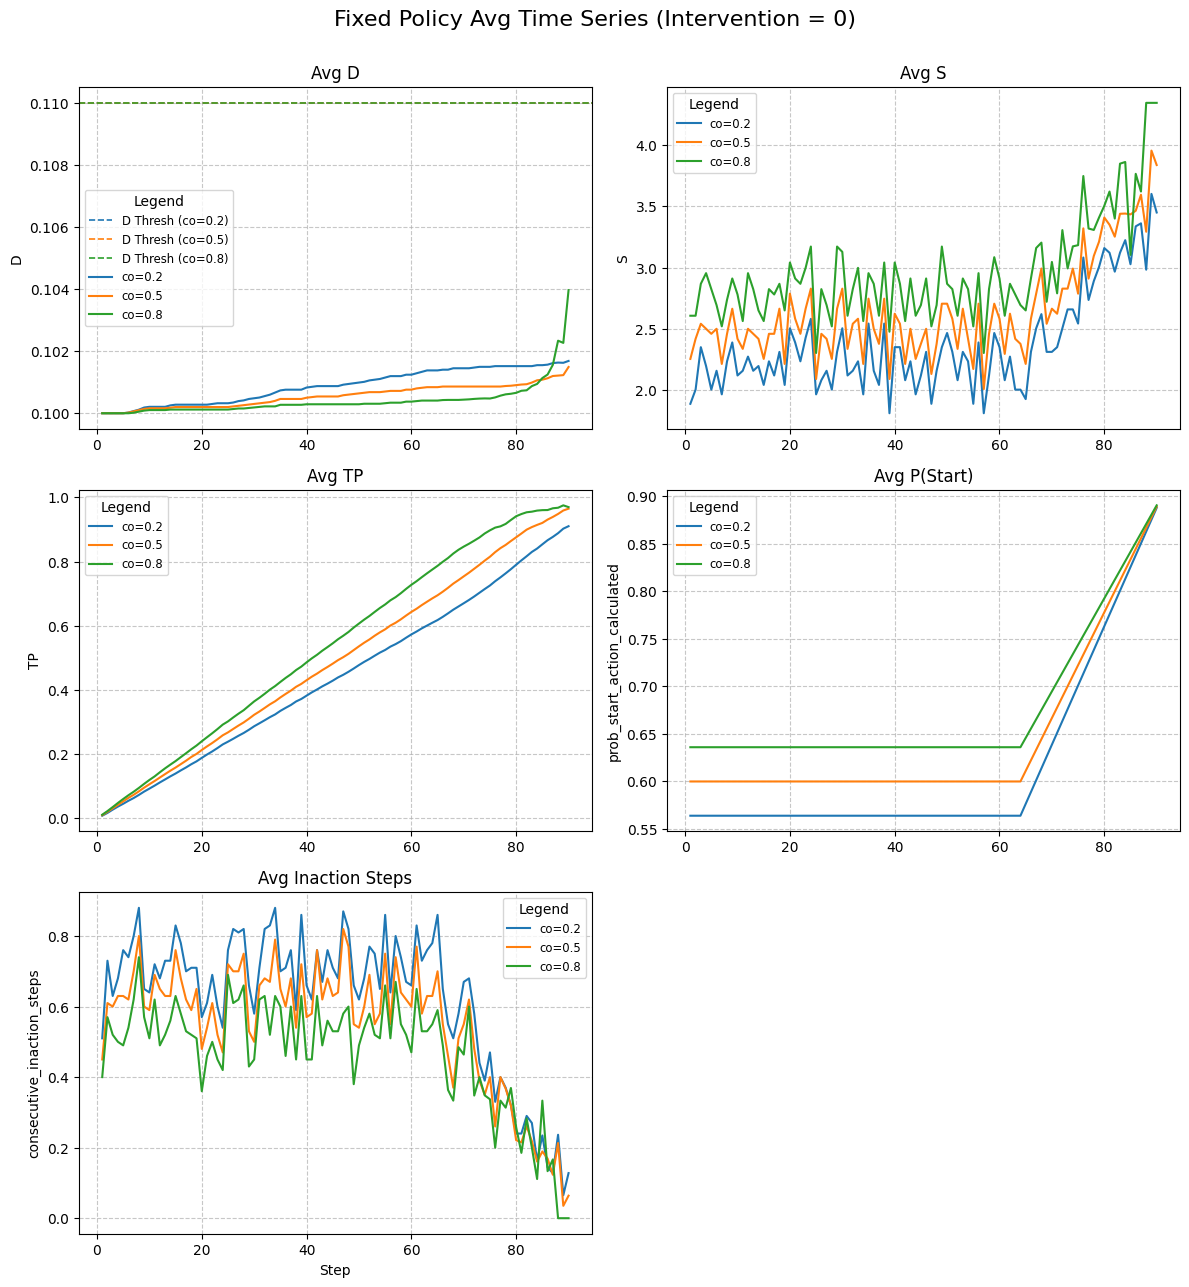


--- Generating fixed policy plots for Intervention Action = 1 ---


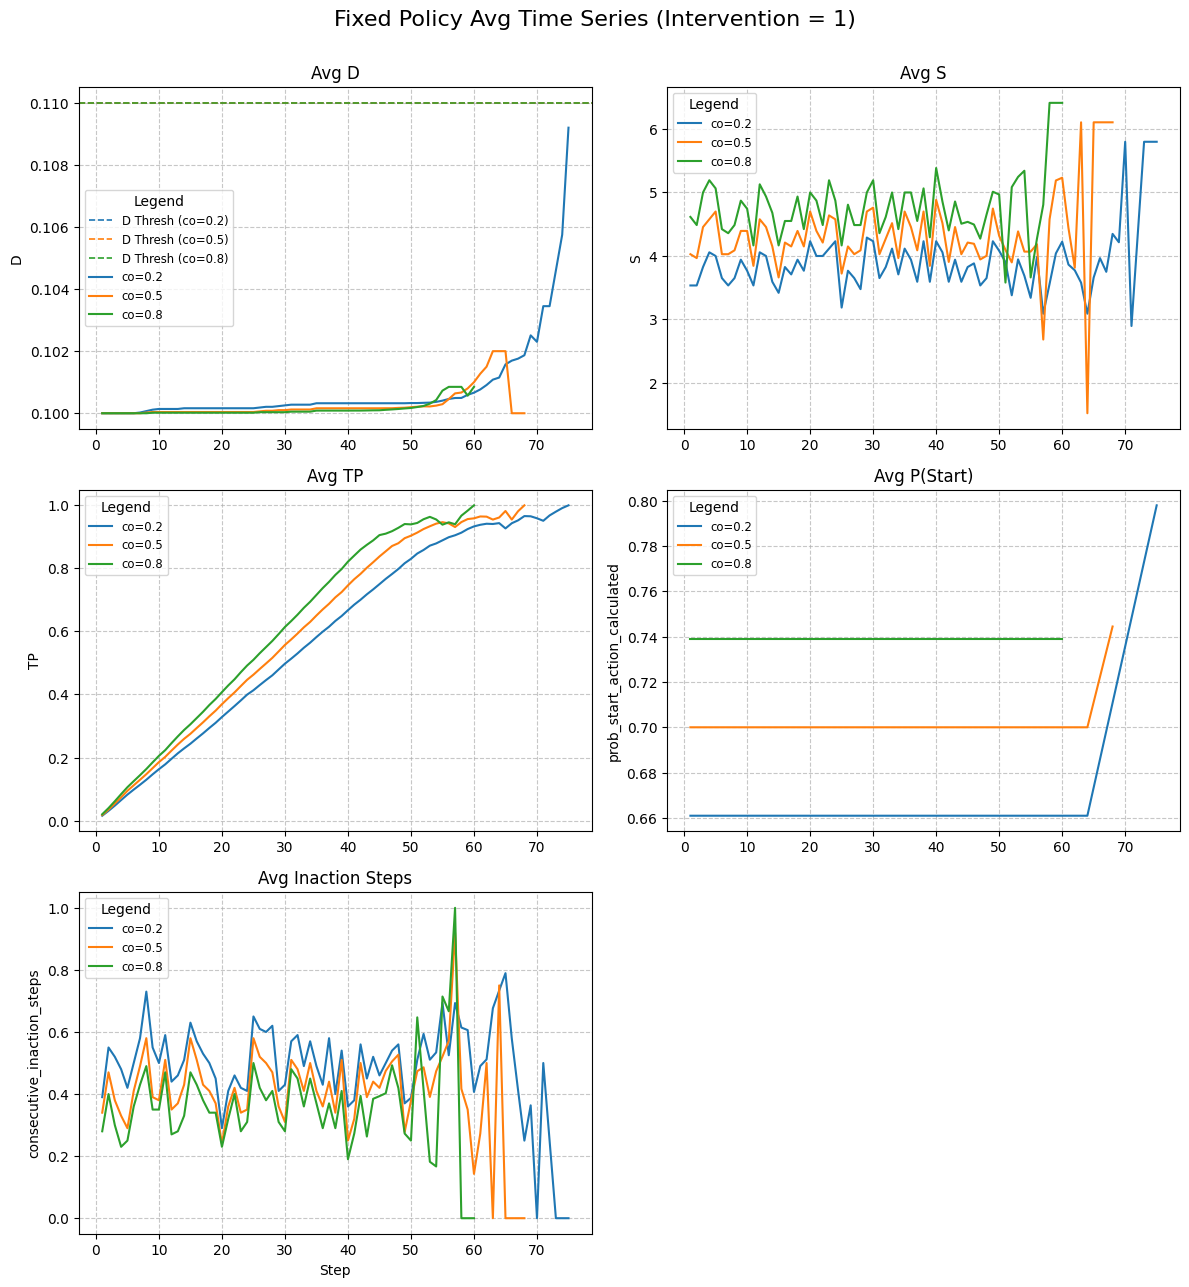


--- Generating fixed policy plots for Intervention Action = 2 ---


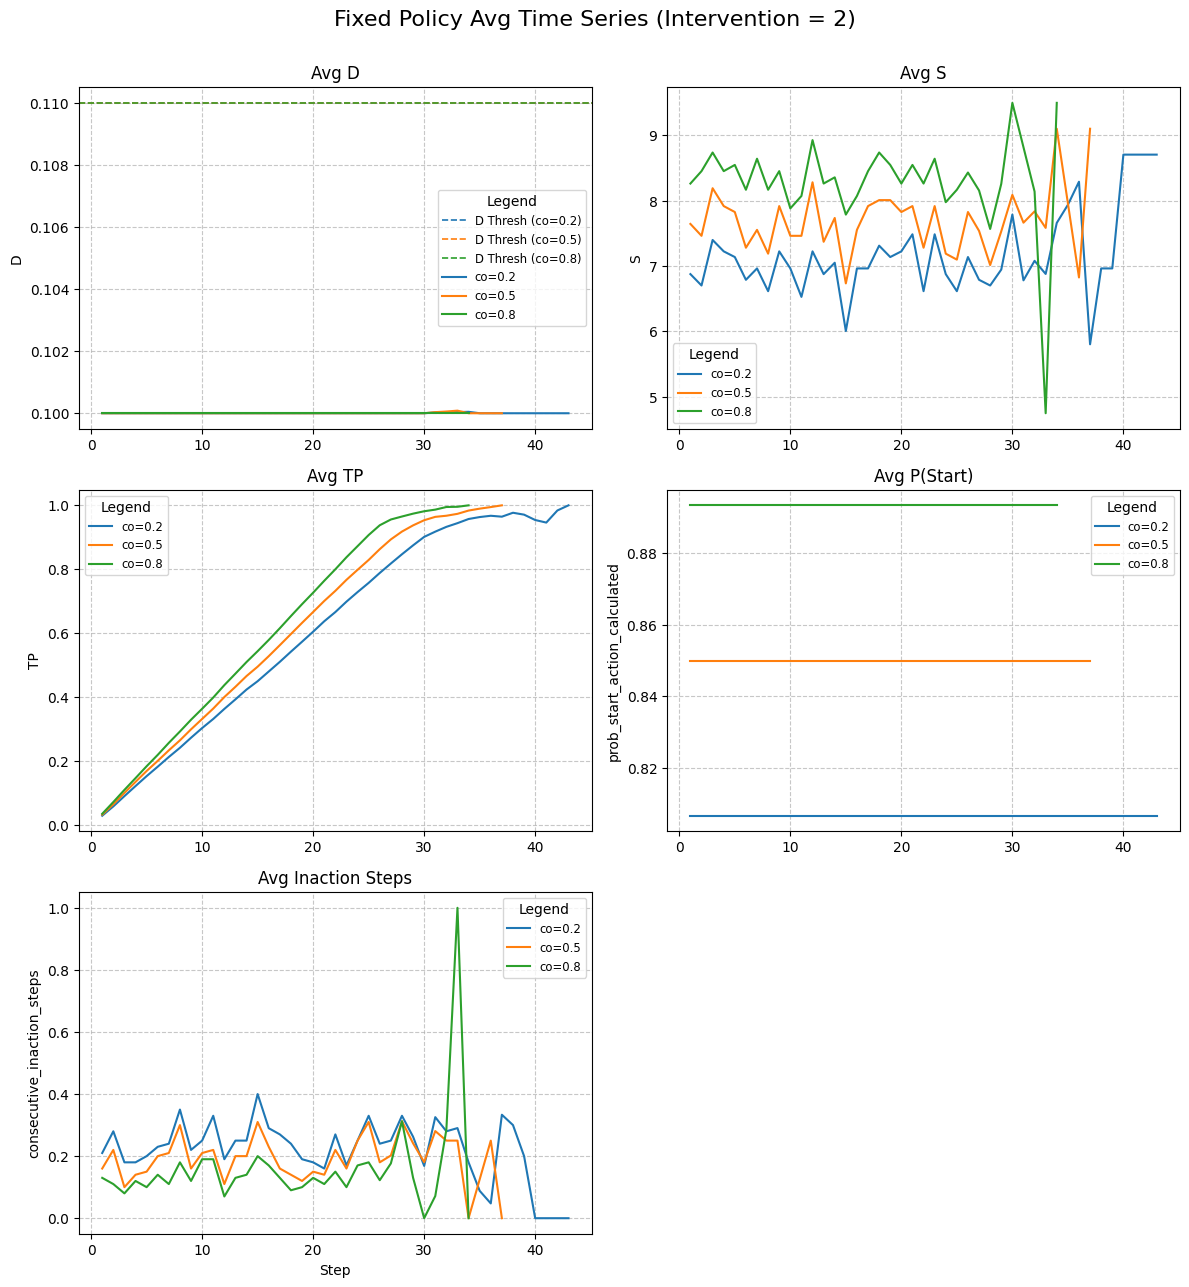


--- 強化学習エージェントの学習と評価 開始 ---
新規モデルを作成して学習を開始します。
Using cpu device
学習中...
Logging to ./ppo_jitai_tensorboard_final/PPO_run_final_1
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 48.5     |
|    ep_rew_mean     | 56.8     |
| time/              |          |
|    fps             | 479      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 47.4        |
|    ep_rew_mean          | 56.9        |
| time/                   |             |
|    fps                  | 362         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008199166 |
|    clip_fraction        | 0.0599      |
|    clip_range           

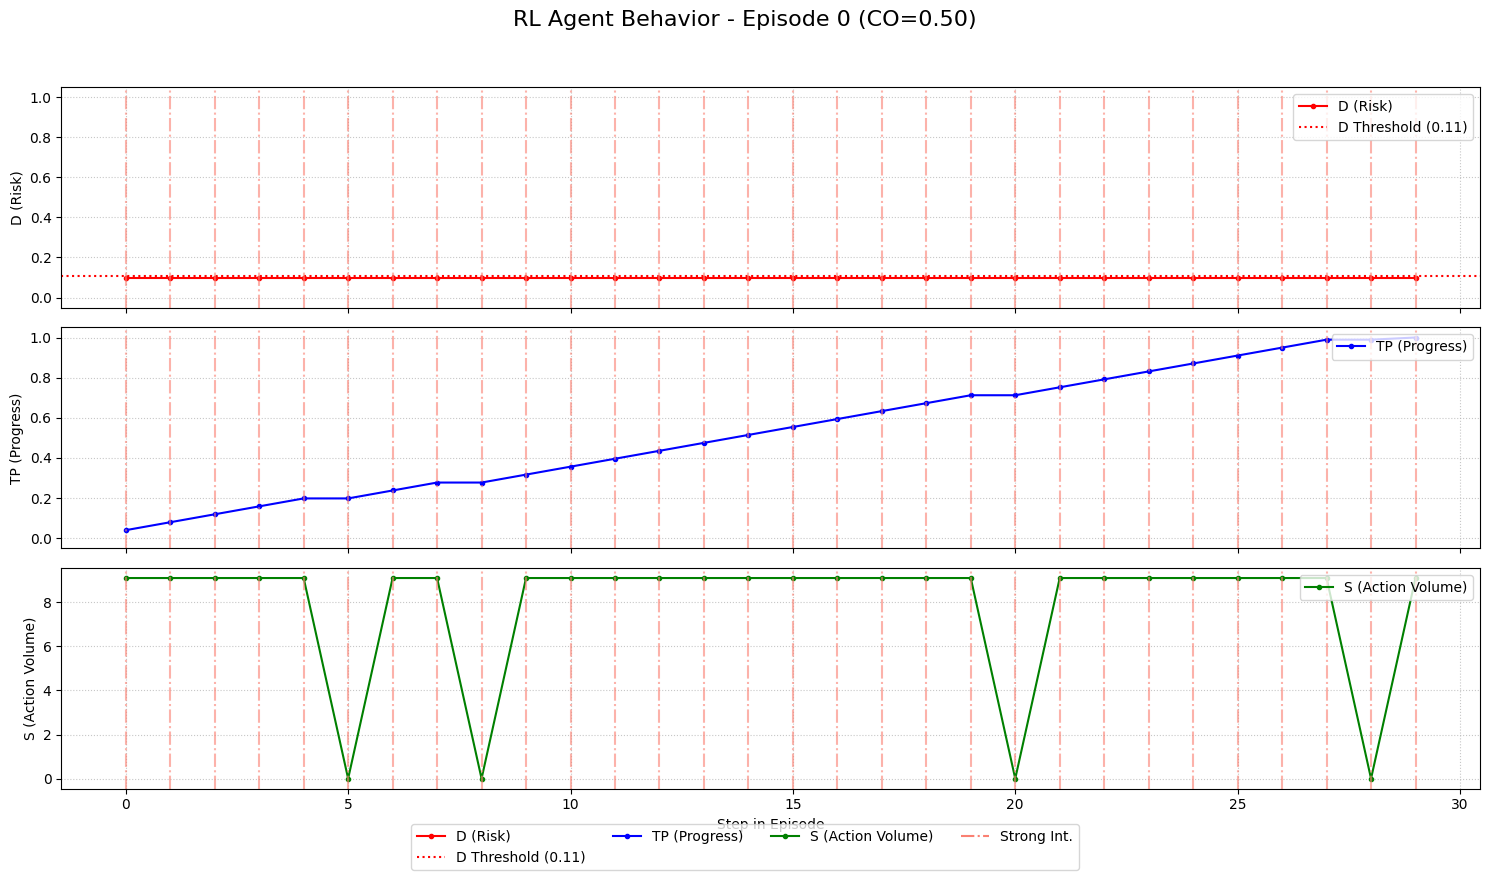

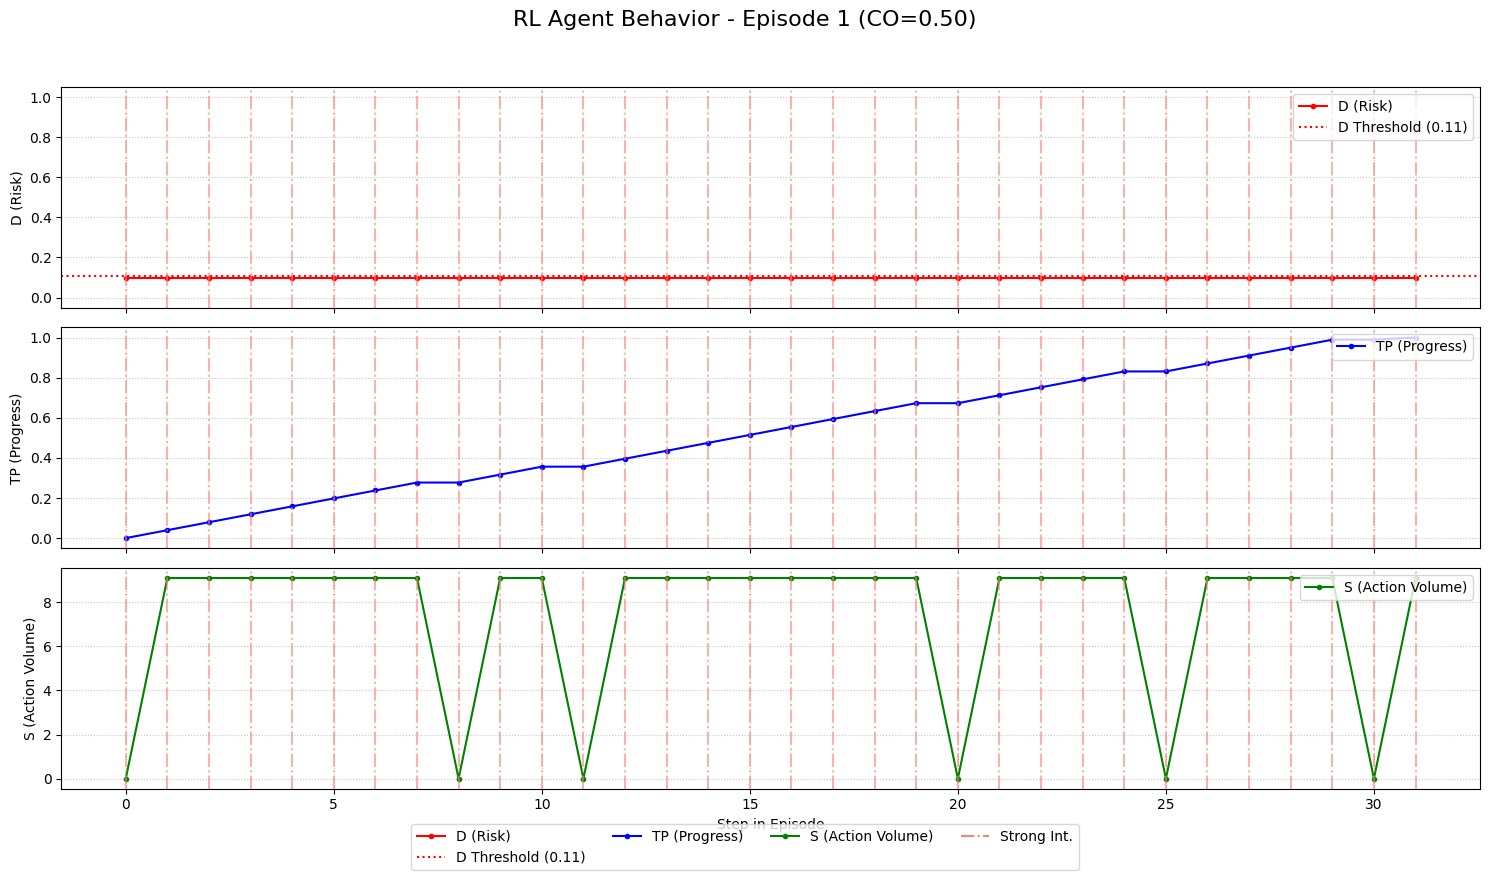


強化学習エージェントの学習と評価 完了。


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import warnings
import pandas as pd
import os
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor

# Matplotlibの日本語設定
try:
    import japanize_matplotlib
    japanize_matplotlib.japanize()
except ImportError:
    print("japanize_matplotlib が見つかりません。日本語表示のためにインストールを検討してください。")
    pass

# Pandasの表示オプション設定
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

class SimplifiedTaskJITAIEnv(gym.Env):
    metadata = {'render_modes': ['human'], 'render_fps': 4}

    def __init__(self,
                 n_actions=3,
                 max_episode_length=90,
                 seed=0,
                 co_score=0.5,
                 total_task_work=230.0,
                 delta_d_base=0.02, # 介入によるD変動削除のため、Dには直接使われなくなる
                 epsilon_d_base=0.05, # 介入によるD変動削除のため、Dには直接使われなくなる
                 D_threshold_base=0.2,
                 d_increase_on_inaction_base=0.002,
                 co_effect_on_d_increase_inaction_multiplier=-0.5,
                 inaction_steps_threshold=5,
                 base_prob_start_action_base=0.6,
                 intervention_boost_to_prob_start_base=[0.0, 0.1, 0.25],
                 urgency_factor_base=0.3,
                 mu_s_base=4.1,
                 rho1_base=2.0,
                 rho2_base=5.0,
                 co_effect_on_delta_d_multiplier=0.3, # D変動削除のため影響なし
                 co_effect_on_epsilon_d_multiplier=0.5, # D変動削除のため影響なし
                 co_effect_on_D_threshold_multiplier=1.5, # D閾値共通化のため影響なし
                 co_effect_on_base_prob_start_multiplier=0.2,
                 co_effect_on_intervention_boost_multiplier=0.1,
                 co_effect_on_urgency_factor_multiplier=-0.4,
                 co_effect_on_mu_s_multiplier=0.2,
                 co_effect_on_rho1_multiplier=0.1,
                 co_effect_on_rho2_multiplier=0.1,
                 init_d=0.1,
                 chosen_obs_names=['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
                 n_version=0,
                 s_noise_std_base=0.0,
                 co_effect_on_s_noise_std_multiplier=0.0,
                 intervention_cost=0.1 # 介入コストを初期化パラメータに追加
                 ):
        super().__init__()

        self.max_episode_length = max_episode_length
        self.n_actions = n_actions
        self.chosen_obs_names = chosen_obs_names
        self.n_version = n_version

        self.co_score = np.clip(co_score, 0.0, 1.0)
        self.current_CO = self.co_score

        self.delta_d_base = delta_d_base
        self.epsilon_d_base = epsilon_d_base
        self.D_threshold_base = D_threshold_base # 共通閾値のベースとして使用
        self.d_increase_on_inaction_base = d_increase_on_inaction_base
        self.co_effect_on_d_increase_inaction_multiplier = co_effect_on_d_increase_inaction_multiplier
        self.inaction_steps_threshold = inaction_steps_threshold

        self.base_prob_start_action_base = base_prob_start_action_base
        self.intervention_boost_to_prob_start_base = np.array(intervention_boost_to_prob_start_base)
        if len(self.intervention_boost_to_prob_start_base) != n_actions:
            raise ValueError("Length of intervention_boost_to_prob_start_base must match n_actions.")
        self.urgency_factor_base = urgency_factor_base
        self.mu_s_base = mu_s_base
        self.rho1_base = rho1_base
        self.rho2_base = rho2_base
        self.total_task_work = total_task_work
        self.s_noise_std_base = s_noise_std_base

        self.co_effect_on_delta_d_multiplier = co_effect_on_delta_d_multiplier
        self.co_effect_on_epsilon_d_multiplier = co_effect_on_epsilon_d_multiplier
        self.co_effect_on_D_threshold_multiplier = co_effect_on_D_threshold_multiplier
        self.co_effect_on_base_prob_start_multiplier = co_effect_on_base_prob_start_multiplier
        self.co_effect_on_intervention_boost_multiplier = co_effect_on_intervention_boost_multiplier
        self.co_effect_on_urgency_factor_multiplier = co_effect_on_urgency_factor_multiplier
        self.co_effect_on_mu_s_multiplier = co_effect_on_mu_s_multiplier
        self.co_effect_on_rho1_multiplier = co_effect_on_rho1_multiplier
        self.co_effect_on_rho2_multiplier = co_effect_on_rho2_multiplier
        self.co_effect_on_s_noise_std_multiplier = co_effect_on_s_noise_std_multiplier

        self.init_d = init_d
        self.init_s = 0.0
        self.init_task_progress = 0.0
        
        self.intervention_cost = intervention_cost # インスタンス変数として保存

        self.seed = seed
        self.rng1 = None # resetで初期化

        self.current_t = 0
        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.consecutive_inaction_steps = 0

        self.action_space = spaces.Discrete(self.n_actions)
        min_obs_values, max_obs_values = self.extract_min_max()
        self.observation_space = spaces.Box(
            low=np.array(min_obs_values, dtype=np.float32),
            high=np.array(max_obs_values, dtype=np.float32),
            dtype=np.float32
        )
        self._initialize_operational_params()

    def _initialize_operational_params(self):
        self.delta_d, self.epsilon_d, self.D_threshold = 0.0, 0.0, 0.0 # delta_d, epsilon_d はD変動には使われない
        self.base_prob_start_action = 0.0
        self.intervention_boost_to_prob_start = np.zeros(self.n_actions)
        self.urgency_factor = 0.0
        self.mu_s, self.rho1, self.rho2 = 0.0, 0.0, 0.0
        self.s_noise_std = 0.0

    def _adjust_param(self, base_val, multiplier, co_factor):
        return base_val * (1 + co_factor * multiplier)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None:
            self.seed = seed
        self.rng1 = np.random.default_rng(self.seed + self.current_t + 1)

        self._initialize_operational_params()
        co_factor = self.co_score - 0.5

        # D閾値は共通 (co_scoreに依存しない)
        self.D_threshold = np.clip(self.D_threshold_base, 0.001, 0.999)
        
        # delta_d, epsilon_d はDの直接変動には使われなくなったが、計算は残しておく (他の用途の可能性)
        self.delta_d = np.clip(self._adjust_param(self.delta_d_base, self.co_effect_on_delta_d_multiplier, co_factor), 0.0, 0.999)
        self.epsilon_d = np.clip(self._adjust_param(self.epsilon_d_base, self.co_effect_on_epsilon_d_multiplier, co_factor), 0.0, 0.999)

        self.base_prob_start_action = np.clip(self._adjust_param(self.base_prob_start_action_base, self.co_effect_on_base_prob_start_multiplier, co_factor), 0.01, 0.99)
        boost_adjustment = (1 + co_factor * self.co_effect_on_intervention_boost_multiplier)
        self.intervention_boost_to_prob_start = np.clip(self.intervention_boost_to_prob_start_base * boost_adjustment, 0.0, 0.5)
        self.urgency_factor = self._adjust_param(self.urgency_factor_base, self.co_effect_on_urgency_factor_multiplier, co_factor)
        self.urgency_factor = np.clip(self.urgency_factor, -0.5, 0.5)
        self.mu_s = np.clip(self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor), 0.1, None)
        self.rho1 = np.clip(self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor), 0.0, None)
        self.rho2 = np.clip(self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor), 0.0, None)

        if self.n_version == 1:
            self.s_noise_std = np.clip(self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor), 0.0, None)
        else:
            self.s_noise_std = 0.0

        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.current_t = 0
        self.consecutive_inaction_steps = 0

        obs = self._get_observation()
        info = self._get_info()
        info.update({"message": "Environment reset."})
        return obs, info

    def step(self, agent_action):
        a = int(agent_action)
        if not (0 <= a < self.n_actions):
            raise ValueError(f"Action {a} is out of range for n_actions={self.n_actions}")

        task_progress_t = self.TaskProgress

        time_remaining_normalized = (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        urgency_effect_on_prob_start = 0.0
        urgency_threshold = 0.3
        if time_remaining_normalized < urgency_threshold and time_remaining_normalized >= 0:
            urgency_level = 1.0 - (time_remaining_normalized / urgency_threshold)
            urgency_effect_on_prob_start = self.urgency_factor * urgency_level

        prob_start_action_calculated = self.base_prob_start_action \
                                         + self.intervention_boost_to_prob_start[a] \
                                         + urgency_effect_on_prob_start
        prob_start_action_calculated = np.clip(prob_start_action_calculated, 0.01, 0.99)

        s_this_step = 0.0
        action_started_this_step = False
        if self.rng1.random() < prob_start_action_calculated:
            action_started_this_step = True
            s_next_mu_calculated = self.mu_s
            if a == 1: s_next_mu_calculated += self.rho1
            elif a == 2: s_next_mu_calculated += self.rho2
            s_final_next_if_started = s_next_mu_calculated
            if self.n_version == 1 and self.s_noise_std > 0:
                s_final_next_if_started = max(0.0, self.rng1.normal(s_next_mu_calculated, self.s_noise_std))
            s_this_step = max(0.0, s_final_next_if_started)
        self.S = s_this_step

        # Dの更新: 非行動による増加のみ
        if not action_started_this_step:
            self.consecutive_inaction_steps += 1
        else:
            self.consecutive_inaction_steps = 0

        d_increased_this_step_due_to_inaction = 0.0
        if self.consecutive_inaction_steps >= self.inaction_steps_threshold:
            co_factor = self.co_score - 0.5
            actual_d_increase = self._adjust_param(
                self.d_increase_on_inaction_base,
                self.co_effect_on_d_increase_inaction_multiplier,
                co_factor
            )
            actual_d_increase = max(0, actual_d_increase)
            self.D = self.D + actual_d_increase
            d_increased_this_step_due_to_inaction = actual_d_increase
        self.D = np.clip(self.D, 0.0, 1.0)

        # TaskProgress の更新
        if self.total_task_work > 1e-9:
            progress_this_step = self.S / self.total_task_work
            self.TaskProgress = np.clip(task_progress_t + progress_this_step, 0.0, 1.0)
        else:
            self.TaskProgress = 1.0 if self.S > 0 else task_progress_t

        # 報酬計算
        step_reward = 0.0
        progress_made_in_step = self.TaskProgress - task_progress_t
        reward_scale_factor = 10.0
        step_reward += progress_made_in_step * reward_scale_factor
        task_completed_this_step = (task_progress_t < 1.0 and self.TaskProgress >= 1.0)
        if task_completed_this_step:
            step_reward += 50.0
        if a == 1 or a == 2: # 介入コスト
            step_reward -= self.intervention_cost

        # 終了判定と情報収集
        terminated = False
        truncated = False
        current_info = self._get_info() # _get_info は調整済みパラメータも返すように拡張すると良い
        current_info["action_taken"] = a
        current_info["action_started_this_step"] = action_started_this_step
        current_info["prob_start_action"] = prob_start_action_calculated
        current_info["urgency_effect_on_prob_start"] = urgency_effect_on_prob_start
        current_info["d_increased_due_to_inaction"] = d_increased_this_step_due_to_inaction

        if task_completed_this_step:
            terminated = True
            current_info['task_completed'] = True
        if self.D >= self.D_threshold and not terminated:
            terminated = True
            current_info['disengaged'] = True
            step_reward -= 20.0
            self.S = 0.0
        
        self.current_t += 1
        if self.current_t >= self.max_episode_length and not terminated:
            truncated = True
            current_info['TimeLimit.truncated'] = True
            if self.TaskProgress < 1.0:
                step_reward -= 10.0

        observation = self._get_observation()
        return observation, float(step_reward), terminated, truncated, current_info

    def _get_observation(self):
        obs_dict = {
            'D': self.D, 'S': self.S, 'TP': self.TaskProgress, 'CO': self.current_CO,
            'TR': (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        }
        obs_values = []
        for obs_name in self.chosen_obs_names:
            if obs_name in obs_dict:
                obs_values.append(obs_dict[obs_name])
            elif obs_name == 'T_parity':
                obs_values.append(self.get_T_parity())
            else:
                obs_values.append(0.0)
                warnings.warn(f"Unknown obs_name '{obs_name}' in chosen_obs_names. Appending 0.0 to observation.", UserWarning)
        return np.array(obs_values, dtype=np.float32)

    def _get_info(self):
        return {
            "current_D": self.D, "current_S": self.S,
            "current_TaskProgress": self.TaskProgress, "current_CO": self.current_CO,
            "current_t": self.current_t,
            "time_remaining_normalized": (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            "consecutive_inaction_steps": self.consecutive_inaction_steps,
            "adjusted_D_threshold": getattr(self, 'D_threshold', None), # resetで計算されたD閾値
            # 必要に応じて他の調整済みパラメータも追加
            "prob_start_action": getattr(self, 'prob_start_action_calculated', None), # step内で計算される値
            "action_started_this_step": getattr(self, 'action_started_this_step', None) # step内で計算される値
        }

    def extract_min_max(self):
        min_values = []; max_values = []
        co_factor_extrema = 0.5
        mu_s_adj_plus = self.mu_s_base * (1 + co_factor_extrema * self.co_effect_on_mu_s_multiplier)
        mu_s_adj_minus = self.mu_s_base * (1 - co_factor_extrema * self.co_effect_on_mu_s_multiplier)
        max_mu_s_adj = max(mu_s_adj_plus, mu_s_adj_minus, self.mu_s_base, 0.1)
        rho2_adj_plus = self.rho2_base * (1 + co_factor_extrema * self.co_effect_on_rho2_multiplier)
        rho2_adj_minus = self.rho2_base * (1 - co_factor_extrema * self.co_effect_on_rho2_multiplier)
        max_rho2_adj = max(rho2_adj_plus, rho2_adj_minus, self.rho2_base)
        s_noise_std_adj_plus = self.s_noise_std_base * (1 + co_factor_extrema * self.co_effect_on_s_noise_std_multiplier) if self.n_version == 1 else 0.0
        s_noise_std_adj_minus = self.s_noise_std_base * (1 - co_factor_extrema * self.co_effect_on_s_noise_std_multiplier) if self.n_version == 1 else 0.0
        max_s_noise_std_adj = max(s_noise_std_adj_plus, s_noise_std_adj_minus, self.s_noise_std_base if self.n_version == 1 else 0.0)
        max_s_noise_std_adj = max(0, max_s_noise_std_adj)
        max_s_estimate = max(0.1, max_mu_s_adj + max_rho2_adj + (5 * max_s_noise_std_adj if self.n_version == 1 else 0.0))
        for check_obs in self.chosen_obs_names:
            if check_obs == 'D': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'S': min_values.append(0.0); max_values.append(max_s_estimate if max_s_estimate > 0 else 1.0)
            elif check_obs == 'TP': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'CO': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'TR': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'T_parity': min_values.append(0.0); max_values.append(1.0)
            else: raise ValueError(f"Unknown obs_name '{check_obs}' in chosen_obs_names for extract_min_max.")
        return min_values, max_values

    def get_T_parity(self):
        return float((self.current_t % 2) == 0)

    def render(self): pass
    def close(self): pass

# --- 固定ポリシーシミュレーション結果用のプロット関数 ---
def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
    # ... (この関数は以前提供したものと同じ) ...
    legend_elements_subplot = {}
    ax.set_title(plot_title)
    ax.set_ylabel(var_name)
    ax.grid(True, linestyle='--', alpha=0.7)
    for co_val in co_scores:
        df_co_specific = df_steps[df_steps['co_score'] == co_val]
        if var_name in df_co_specific.columns and not df_co_specific.empty:
            try:
                pivot_df = df_co_specific.pivot_table(index='step', columns='run_id', values=var_name)
                avg_series = pivot_df.mean(axis=1)
                if not avg_series.empty:
                    line, = ax.plot(avg_series.index, avg_series.values, label=f'co={co_val:.1f}')
                    legend_elements_subplot[f'co={co_val:.1f}'] = line
                    if var_name == 'D' and 'D_threshold_value' in df_co_specific.columns:
                        valid_thresholds = df_co_specific['D_threshold_value'].dropna()
                        if not valid_thresholds.empty:
                            d_thresh_for_co = valid_thresholds.iloc[0]
                            line_color = line.get_color()
                            threshold_legend_label = f'D Thresh (co={co_val:.1f})'
                            ax.axhline(d_thresh_for_co, color=line_color, linestyle='--', linewidth=1.2, alpha=0.9)
                            if threshold_legend_label not in legend_elements_subplot:
                                dummy_line, = ax.plot([], [], color=line_color, linestyle='--', linewidth=1.2, label=threshold_legend_label)
                                legend_elements_subplot[threshold_legend_label] = dummy_line
            except Exception as e:
                print(f"プロットエラー (サブプロット内関数): {var_name} for co_score={co_val}. Error: {e}")
    if show_xlabel:
        ax.set_xlabel('Step')
    if legend_elements_subplot:
        sorted_legend_items = sorted(legend_elements_subplot.items(), key=lambda item: item[0])
        ax.legend([item[1] for item in sorted_legend_items], [item[0] for item in sorted_legend_items], title='Legend', loc='best', fontsize='small')

# --- 強化学習エージェントの行動可視化用のプロット関数 ---
def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
    # ... (この関数は以前提供したものと同じ) ...
    episode_data = df_all_eval_steps[df_all_eval_steps['episode_id'] == episode_id_to_plot].copy()
    if episode_data.empty:
        print(f"エピソード {episode_id_to_plot} のデータがありません。")
        return

    co_score_episode = episode_data['CO'].iloc[0] if 'CO' in episode_data.columns and not episode_data['CO'].empty else env_config.get("co_score", 0.5)

    if 'D_threshold_value' in episode_data.columns and not episode_data['D_threshold_value'].isnull().all():
         d_threshold = episode_data['D_threshold_value'].dropna().iloc[0]
    else:
        co_factor = co_score_episode - 0.5
        d_thresh_base = env_config.get('D_threshold_base', 0.2)
        # D閾値がco_scoreに依存しない共通値の場合 (co_effect_on_D_threshold_multiplier を使わない)
        d_threshold = np.clip(d_thresh_base, 0.001, 0.999)
        # もしco_score依存にする場合は以下のコメントアウトを解除し、引数やenv_config_baseのキーを確認
        # co_eff_d_thresh = env_config.get('co_effect_on_D_threshold_multiplier', 0) # 0なら影響なし
        # adjusted_d_threshold = d_thresh_base * (1 + co_factor * co_eff_d_thresh)
        # d_threshold = np.clip(adjusted_d_threshold, 0.001, 0.999)


    intervention_styles = {
        0: {'color': 'lightgray', 'linestyle': ':', 'label': 'No Int.'},
        1: {'color': 'skyblue', 'linestyle': '--', 'label': 'Weak Int.'},
        2: {'color': 'salmon', 'linestyle': '-.', 'label': 'Strong Int.'}
    }
    num_subplots = 3
    fig, axes = plt.subplots(num_subplots, 1, figsize=(15, num_subplots * 3), sharex=True)
    fig.suptitle(f'RL Agent Behavior - Episode {episode_id_to_plot} (CO={co_score_episode:.2f})', fontsize=16)

    axes[0].plot(episode_data['step'], episode_data['D'], marker='.', linestyle='-', color='red', label='D (Risk)')
    axes[0].axhline(y=d_threshold, color='red', linestyle=':', linewidth=1.5, label=f'D Threshold ({d_threshold:.2f})')
    axes[0].set_ylabel('D (Risk)')
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle=':', alpha=0.7)

    axes[1].plot(episode_data['step'], episode_data['TP'], marker='.', linestyle='-', color='blue', label='TP (Progress)')
    axes[1].set_ylabel('TP (Progress)')
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].legend(loc='upper right')
    axes[1].grid(True, linestyle=':', alpha=0.7)
    
    axes[2].plot(episode_data['step'], episode_data['S'], marker='.', linestyle='-', color='green', label='S (Action Volume)')
    axes[2].set_ylabel('S (Action Volume)')
    axes[2].legend(loc='upper right')
    axes[2].grid(True, linestyle=':', alpha=0.7)
    axes[2].set_xlabel('Step in Episode')

    action_legend_handles_generated = {}
    for i in range(num_subplots):
        for _, row in episode_data.iterrows():
            action = int(row['action_taken'])
            step = row['step']
            style = intervention_styles.get(action)
            if style:
                axes[i].axvline(x=step, color=style['color'], linestyle=style['linestyle'], alpha=0.6, linewidth=1.5)
                if style['label'] not in action_legend_handles_generated:
                    action_legend_handles_generated[style['label']] = plt.Line2D([0], [0], color=style['color'], linestyle=style['linestyle'], linewidth=1.5)
    
    handles, labels = [], []
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for handle, label_text in zip(h,l):
            if label_text not in labels: handles.append(handle); labels.append(label_text)
    for label_text, handle in action_legend_handles_generated.items():
        if label_text not in labels: handles.append(handle); labels.append(label_text)
    if handles: fig.legend(handles, labels, loc='lower center', ncol=min(len(handles), 4), bbox_to_anchor=(0.5, 0.05 / num_subplots ))
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()


if __name__ == '__main__':
    RUN_FIXED_POLICY_SIMULATIONS = True  # 固定ポリシーシミュレーションを実行するかどうか
    RUN_RL_TRAINING_AND_EVALUATION = True # 強化学習を実行するかどうか

    # --- 1. env_config_base の定義 ---
    env_config_base = {
        "n_actions": 3, "max_episode_length": 90, "total_task_work": 230.0,
        "delta_d_base": 0.0002, "epsilon_d_base": 0.05, "D_threshold_base": 0.11, # D閾値はresetで共通化
        "d_increase_on_inaction_base": 0.002, "co_effect_on_d_increase_inaction_multiplier": -0.5,
        "inaction_steps_threshold": 5, "base_prob_start_action_base": 0.6,
        "intervention_boost_to_prob_start_base": [0.0, 0.1, 0.25], "urgency_factor_base": 0.3,
        "mu_s_base": 4.1, "rho1_base": 2.0, "rho2_base": 5.0,
        "co_effect_on_delta_d_multiplier": 0.3, "co_effect_on_epsilon_d_multiplier": 0.5,
        "co_effect_on_D_threshold_multiplier": 0, # D閾値共通化のため0に (resetで使われないが念のため)
        "co_effect_on_base_prob_start_multiplier": 0.2, "co_effect_on_intervention_boost_multiplier": 0.1,
        "co_effect_on_urgency_factor_multiplier": -0.4, "co_effect_on_mu_s_multiplier": 0.2,
        "co_effect_on_rho1_multiplier": 0.1, "co_effect_on_rho2_multiplier": 0.1,
        "intervention_cost": 0.1, "init_d": 0.1,
        "chosen_obs_names": ['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
        "n_version": 0, "s_noise_std_base": 0.0, "co_effect_on_s_noise_std_multiplier": 0.0
    }

    if RUN_FIXED_POLICY_SIMULATIONS:
        print("--- 固定ポリシーでのシミュレーション開始 ---")
        actions_to_simulate_list = [0, 1, 2]
        co_score_levels_to_test = [0.2, 0.5, 0.8]
        num_runs_per_condition = 100 # 本格的な場合は100以上

        all_step_data_list = []
        episode_summary_list = []

        for current_simulated_action in actions_to_simulate_list:
            print(f"\n===== シミュレーション中: 介入 = {current_simulated_action} =====")
            for co_score_val in co_score_levels_to_test:
                current_env_params = env_config_base.copy()
                current_env_params["co_score"] = co_score_val
                for i in range(num_runs_per_condition):
                    env_fixed_policy = SimplifiedTaskJITAIEnv(**current_env_params, seed=i) # 新しいインスタンス
                    obs, info = env_fixed_policy.reset(seed=i)
                    terminated, truncated, episode_steps = False, False, 0
                    while not (terminated or truncated):
                        action_to_take_in_env = current_simulated_action
                        obs, reward, terminated, truncated, info_step = env_fixed_policy.step(action_to_take_in_env)
                        episode_steps += 1
                        step_data_entry = {
                            'run_id': i, 'simulated_action': current_simulated_action,
                            'co_score': co_score_val, 'step': episode_steps,
                            'current_t_env': env_fixed_policy.current_t, 'D': env_fixed_policy.D, 'S': env_fixed_policy.S, 'TP': env_fixed_policy.TaskProgress,
                            'action_taken_in_env': action_to_take_in_env,
                            'D_threshold_value': info_step.get('adjusted_D_threshold'), # _get_info() から取得
                            'prob_start_action_calculated': info_step.get('prob_start_action'),
                            'urgency_effect_on_prob_start': info_step.get('urgency_effect_on_prob_start'),
                            'consecutive_inaction_steps': env_fixed_policy.consecutive_inaction_steps,
                            'd_increased_this_step_due_to_inaction': info_step.get('d_increased_due_to_inaction', 0.0),
                            'action_started_this_step': info_step.get('action_started_this_step', False) # 追加
                        }
                        all_step_data_list.append(step_data_entry)
                    task_completed = info_step.get('task_completed', False)
                    disengaged = info_step.get('disengaged', False)
                    timed_out = truncated and not task_completed and not disengaged
                    episode_summary_list.append({
                        'run_id': i, 'simulated_action': current_simulated_action, 'co_score': co_score_val,
                        'steps': episode_steps, 'completed': task_completed, 'disengaged': disengaged, 'timed_out': timed_out,
                        'final_D': env_fixed_policy.D, 'final_TP': env_fixed_policy.TaskProgress
                    })
        print("\n固定ポリシーシミュレーション完了。")

        df_step_data = pd.DataFrame(all_step_data_list)
        df_step_data.to_csv('simulation_all_actions_step_data.csv', index=False)
        print("\n詳細ステップデータ(固定ポリシー)が 'simulation_all_actions_step_data.csv' に保存されました。")
        df_episode_summary = pd.DataFrame(episode_summary_list)
        df_episode_summary.to_csv('simulation_all_actions_episode_summary.csv', index=False)
        print("エピソードサマリーデータ(固定ポリシー)が 'simulation_all_actions_episode_summary.csv' に保存されました。")

        print("\n--- 固定ポリシー結果のCSVデータからの分析と可視化 ---")
        try:
            df_episode_loaded_fixed = pd.read_csv('simulation_all_actions_episode_summary.csv')
            df_steps_loaded_fixed = pd.read_csv('simulation_all_actions_step_data.csv')
        except FileNotFoundError:
            print("固定ポリシーのCSVファイルが見つかりません。")
            df_episode_loaded_fixed, df_steps_loaded_fixed = pd.DataFrame(), pd.DataFrame()

        if not df_episode_loaded_fixed.empty:
            print("\n--- 集計表 (介入別、誠実性スコア別 - 固定ポリシー) ---")
            summary_table_fixed = df_episode_loaded_fixed.groupby(['simulated_action', 'co_score']).agg(
                num_episodes=('run_id', 'count'), completion_rate=('completed', 'mean'),
                disengagement_rate=('disengaged', 'mean'), timeout_rate=('timed_out', 'mean'),
                avg_steps_if_completed=('steps', lambda x: df_episode_loaded_fixed.loc[x.index[df_episode_loaded_fixed.loc[x.index, 'completed'] == True], 'steps'].mean()),
                avg_total_steps=('steps', 'mean')
            ).reset_index()
            summary_table_fixed[['completion_rate', 'disengagement_rate', 'timeout_rate']] *= 100
            print(summary_table_fixed)
            
            summary_table_fixed_csv_path = 'fixed_policy_summary_table_aggregated.csv'
            summary_table_fixed.to_csv(summary_table_fixed_csv_path, index=False, encoding='utf-8-sig')
            print(f"\n固定ポリシー集計表は '{summary_table_fixed_csv_path}' にも保存されました。")


        if not df_steps_loaded_fixed.empty:
            print("\n--- 固定ポリシー結果の時系列グラフ ---")
            variables_to_plot = ['D', 'S', 'TP', 'prob_start_action_calculated', 'consecutive_inaction_steps']
            plot_titles_base = {'D': 'Avg D', 'S': 'Avg S', 'TP': 'Avg TP', 'prob_start_action_calculated': 'Avg P(Start)', 'consecutive_inaction_steps': 'Avg Inaction Steps'}
            unique_simulated_actions_in_data = sorted(df_steps_loaded_fixed['simulated_action'].unique())
            for plot_action_val in unique_simulated_actions_in_data:
                print(f"\n--- Generating fixed policy plots for Intervention Action = {plot_action_val} ---")
                df_to_plot_for_action = df_steps_loaded_fixed[df_steps_loaded_fixed['simulated_action'] == plot_action_val]
                if df_to_plot_for_action.empty: continue
                co_scores_for_plotting = sorted(df_to_plot_for_action['co_score'].unique())
                num_vars = len(variables_to_plot)
                n_cols = 2 if num_vars > 2 else num_vars; n_rows = (num_vars + n_cols - 1) // n_cols
                fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 4.5), squeeze=False)
                axes = axes.flatten()
                for i, var_name in enumerate(variables_to_plot):
                    if i < len(axes):
                        ax = axes[i]; title = plot_titles_base.get(var_name, var_name)
                        show_xlabel_flag = (i // n_cols == n_rows - 1) or ((i // n_cols == (num_vars -1)//n_cols) and (i % n_cols < num_vars % n_cols if num_vars % n_cols !=0 else n_cols))
                        plot_average_time_series_subplot(ax, df_to_plot_for_action, var_name, co_scores_for_plotting, title, show_xlabel_flag)
                for j in range(num_vars, len(axes)): fig.delaxes(axes[j])
                plt.tight_layout(rect=[0, 0.03, 1, 0.95]); fig.suptitle(f"Fixed Policy Avg Time Series (Intervention = {plot_action_val})", fontsize=16)
                plt.show()
    else:
        print("--- 固定ポリシーでのシミュレーションはスキップされました ---")


    if RUN_RL_TRAINING_AND_EVALUATION:
        print("\n--- 強化学習エージェントの学習と評価 開始 ---")
        rl_env_config = env_config_base.copy()
        rl_env_config["co_score"] = 0.5 # RLエージェントは特定のco_scoreで学習・評価
        
        def make_env_rl(): # RL用に名前を変更
            env_rl_instance = SimplifiedTaskJITAIEnv(**rl_env_config)
            env_rl_instance = Monitor(env_rl_instance)
            return env_rl_instance
        env_rl_vectorized = DummyVecEnv([make_env_rl])

        model_save_path = "ppo_jitai_agent_final"
        tensorboard_log_path = "./ppo_jitai_tensorboard_final/"
        os.makedirs(tensorboard_log_path, exist_ok=True)

        if os.path.exists(model_save_path + ".zip"):
            print(f"学習済みモデル {model_save_path}.zip をロードします。")
            model = PPO.load(model_save_path, env=env_rl_vectorized)
        else:
            print(f"新規モデルを作成して学習を開始します。")
            model = PPO("MlpPolicy", env_rl_vectorized, verbose=1, tensorboard_log=tensorboard_log_path,
                        learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                        gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, vf_coef=0.5, max_grad_norm=0.5)
            print("学習中...")
            model.learn(total_timesteps=200000, tb_log_name="PPO_run_final") # ステップ数を調整
            model.save(model_save_path)
            print(f"学習済みモデルを {model_save_path}.zip に保存しました。")

        print("\n--- 学習済みRLエージェントの行動記録と評価 ---")
        num_record_episodes = 3
        rl_eval_step_data_list = []
        total_rewards_eval, total_steps_eval, completed_count_eval, disengaged_count_eval, timed_out_count_eval = 0,0,0,0,0
        
        obs_rl = env_rl_vectorized.reset()
        for episode_idx in range(num_record_episodes):
            episode_reward, episode_steps_count, done_in_episode = 0,0,False
            last_info_dict = {}
            while not done_in_episode:
                current_step_in_episode = episode_steps_count
                action_vec, _states = model.predict(obs_rl, deterministic=True)
                action_scalar = action_vec[0]
                new_obs_rl, rewards, dones, infos = env_rl_vectorized.step(action_vec)
                reward_scalar, done_in_episode, info_dict = rewards[0], dones[0], infos[0]
                
                # step_data_entry に D_threshold_value を追加
                step_data_entry = {
                    'episode_id': episode_idx, 'step': current_step_in_episode, 'action_taken': action_scalar,
                    'reward': reward_scalar, 'D': info_dict.get('current_D'), 'S': info_dict.get('current_S'),
                    'TP': info_dict.get('current_TaskProgress'), 'CO': info_dict.get('current_CO'),
                    'TR': info_dict.get('time_remaining_normalized'),
                    'D_threshold_value': info_dict.get('adjusted_D_threshold'), # ここで記録
                    'consecutive_inaction_steps': info_dict.get('consecutive_inaction_steps'),
                    'prob_start_action_calculated': info_dict.get('prob_start_action'),
                    'task_completed': info_dict.get('task_completed', False), 'disengaged': info_dict.get('disengaged', False),
                    'TimeLimit.truncated': info_dict.get('TimeLimit.truncated', False)
                }
                rl_eval_step_data_list.append(step_data_entry)
                
                obs_rl = new_obs_rl
                episode_reward += reward_scalar; episode_steps_count += 1; last_info_dict = info_dict
            
            total_rewards_eval += episode_reward; total_steps_eval += episode_steps_count
            if last_info_dict.get('task_completed', False): completed_count_eval += 1
            elif last_info_dict.get('disengaged', False): disengaged_count_eval += 1
            elif done_in_episode:
                if last_info_dict.get('TimeLimit.truncated', False) and not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                    timed_out_count_eval += 1
                elif not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                     timed_out_count_eval +=1
            print(f"RL評価エピソード {episode_idx + 1} 終了: 報酬={episode_reward:.2f}, ステップ数={episode_steps_count}")

        df_rl_eval_steps = pd.DataFrame(rl_eval_step_data_list)
        if not df_rl_eval_steps.empty:
            df_rl_eval_steps.to_csv("rl_agent_evaluation_steps.csv", index=False)
            print("\nRLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。")
        else:
            print("\nRLエージェントのステップ毎データは記録されませんでした。")

        if num_record_episodes > 0:
            print(f"\nRL評価エピソード数: {num_record_episodes}")
            print(f"平均報酬: {total_rewards_eval / num_record_episodes:.2f}")
            print(f"平均ステップ数: {total_steps_eval / num_record_episodes:.2f}")
            print(f"完了率: {completed_count_eval / num_record_episodes * 100:.1f}%")
            print(f"離脱率: {disengaged_count_eval / num_record_episodes * 100:.1f}%")
            print(f"タイムアウト率: {timed_out_count_eval / num_record_episodes * 100:.1f}%")
        
        if not df_rl_eval_steps.empty:
            plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=0, env_config=rl_env_config)
            if num_record_episodes > 1: # 記録したエピソードが複数あれば2つ目もプロット
                 plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=1, env_config=rl_env_config)

        env_rl_vectorized.close()
        print("\n強化学習エージェントの学習と評価 完了。")
    else:
        print("--- 強化学習エージェントの学習と評価はスキップされました ---")